# IAU – Fáza 1: Prieskumná analýza

**Dataset:** 174

| Autor | Podiel práce | Vypracované časti |
|---|---|---|
| Marcel Novomeský | 34 % | 1.1 (A - E) |
| Ondrej Nebus | 66 % | 1.2, 1.3 |

## Importovanie modulov

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

## Načítanie dát
Dataset č. 174 obsahuje 3 súbory, pričom každý používa iný oddeľovač:
`readings.csv` (tabulátor), `units.csv` (čiarka) a `gateways.csv` (bodkočiarka).
Súbory ukladáme do objektu `data`.

In [2]:
readings = pd.read_csv('174/readings.csv', sep='\t')
units    = pd.read_csv('174/units.csv',    sep=',')
gateways = pd.read_csv('174/gateways.csv', sep=';')

data = {'readings': readings, 'units': units, 'gateways': gateways}

## Analýza štruktúr dát (A)
### súbor readings:

In [3]:
df = data['readings']
print('shape (rows, cols):', df.shape)
print('duplicated rows:', df.duplicated().sum())
df.info()
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes,
        'missing': df.isna().sum(),
        'missing_%': (df.isna().mean() * 100).round(2),
        'unique': df.nunique()}))
print('cycleTs format sample:', df['cycleTs'].sample(10, random_state=1).tolist())


shape (rows, cols): (12288, 14)
duplicated rows: 182
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12288 entries, 0 to 12287
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   unitId              12288 non-null  object 
 1   cycleTs             12288 non-null  object 
 2   current_motor       12288 non-null  float64
 3   dp_filter           11800 non-null  float64
 4   oil_temperature     12288 non-null  float64
 5   pressureReservoir   12288 non-null  float64
 6   pressureWorking     12288 non-null  float64
 7   pressureOil         12288 non-null  float64
 8   rms_vibration       11815 non-null  float64
 9   flowmeter           12288 non-null  float64
 10  noise_ambient       12288 non-null  float64
 11  tempBearing         12288 non-null  float64
 12  discharge_dewpoint  12288 non-null  float64
 13  failure             12288 non-null  int64  
dtypes: float64(11), int64(1), object(2)
memory usage:

,unitId,cycleTs,current_motor,dp_filter,oil_temperature,pressureReservoir,pressureWorking,pressureOil,rms_vibration,flowmeter,noise_ambient,tempBearing,discharge_dewpoint,failure
0,U00056,"04/18/2023, 10:57:00",2.32187,25.05155,41.14680,9.20081,8.96211,3.30202,1.62831,27.64440,80.72804,53.04241,-1.20511,0
1,U00129,2023/03/03,6.42122,14.19480,49.54965,9.31001,9.26212,4.45555,NaN,27.05999,78.43316,58.66861,4.72948,0
2,U00997,2023/03/19,4.49244,15.78431,64.73914,8.88219,8.70972,3.47854,1.43547,25.52708,73.50406,62.10361,8.59171,0
3,U01733,2023-04-14,4.85256,31.03897,66.91948,8.69730,8.76736,3.47469,2.58168,26.19582,75.64485,61.51396,10.24782,0
4,U01011,2023-11-11,5.63082,21.88368,67.62342,9.65397,9.41070,4.66037,5.23571,21.32917,72.19562,59.05902,14.70833,1


,dtype,missing,missing_%,unique
unitId,object,0,0.00,2114
cycleTs,object,0,0.00,4150
current_motor,float64,0,0.00,11984
dp_filter,float64,488,3.97,11599
oil_temperature,float64,0,0.00,12053
pressureReservoir,float64,0,0.00,11748
pressureWorking,float64,0,0.00,11744
pressureOil,float64,0,0.00,11742
rms_vibration,float64,473,3.85,11480
flowmeter,float64,0,0.00,12020


cycleTs format sample: ['07/20/2023, 00:27:00', '17 Jan 2023', '2023-06-09', '22 Aug 2023', '26 Oct 2023', '2023-11-06', '28 Jun 2023', '2023-02-20', '01/25/2023, 12:20:00', '2023/10/14']


**Zhrnutie `readings`**

| Vlastnosť | Hodnota |
|---|---|
| Počet záznamov | 12 288 |
| Počet atribútov | 14 |
| Duplicitné riadky | 182 |
| Unikátne jednotky (`unitId`) | 2 114 |

- **Štruktúra:** každý riadok predstavuje jedno meranie APU jednotky. Obsahuje identifikátor jednotky `unitId`, časovú značku `cycleTs`, 11 numerických senzorových atribútov a cieľovú premennú `failure`.
- **Dátové typy:** senzorové hodnoty sú `float64`, `failure` je `int64` (binárna, 0/1). Atribúty `unitId` a `cycleTs` sú uložené ako text (`object`).
- **Nejednotný formát dátumu:** `cycleTs` obsahuje dátumy v rôznych formátoch (napr. `2023-06-09`, `2023/10/14`, `07/20/2023, 00:27:00`, `17 Jan 2023`).
- **Chýbajúce hodnoty:** `dp_filter` (488 = 3,97 %) a `rms_vibration` (473 = 3,85 %). Keďže ide o malý podiel, v časti 1.2 ich plánujeme doplniť namiesto odstránenia celých riadkov.
- **Duplicity:** 182 úplne zhodných riadkov, ktoré v časti 1.2 odstránime.
- **Viac meraní na jednotku:** 12 288 záznamov patrí 2 114 jednotkám, teda v priemere približne 6 meraní na jednotku.


### súbor units:

In [4]:
df = data['units']
print('shape (rows, cols):', df.shape)
print('duplicated rows:', df.duplicated().sum())
df.info()
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes,
        'missing': df.isna().sum(),
        'missing_%': (df.isna().mean() * 100).round(2),
        'unique': df.nunique()}))

shape (rows, cols): (2000, 12)
duplicated rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_serial   2000 non-null   object 
 1   yearCommission  2000 non-null   int64  
 2   ownerOperator   2000 non-null   object 
 3   unitId          2000 non-null   int64  
 4   manufacturer    2000 non-null   object 
 5   class_duty      2000 non-null   object 
 6   idDepot         2000 non-null   int64  
 7   install_region  2000 non-null   object 
 8   code_line       2000 non-null   object 
 9   codeModel       2000 non-null   object 
 10  last_overhaul   2000 non-null   object 
 11  hours_service   1900 non-null   float64
dtypes: float64(1), int64(3), object(8)
memory usage: 187.6+ KB


,number_serial,yearCommission,ownerOperator,unitId,manufacturer,class_duty,idDepot,install_region,code_line,codeModel,last_overhaul,hours_service
0,BM-1229-13076,2022,Zorbach Hellwig GbR,1,Cardoso Mendes S.A.,L,27,Sangerhausen,L3,APU-12,2020/12/25,9469.5
1,LG-7446-96671,2020,Jones Inc,2,Fonseca S/A,L,8,Vila do Conde,L6,APU-12,2017/04/04,NaN
2,AP-2437-24985,2024,Pinto,3,Parker-Garcia,H,95,Matosinhos,L6,APU-20,2021-06-27,2340.4
3,AN-4946-59962,2018,Patberg,4,Nichols-Alvarez,med,47,Riveraborough,L4,APU-15,"03/21/2023, 00:00:00",24052.8
4,LO-1685-70016,2017,Kabus GmbH & Co. KG,5,Atkinson-Cantrell,light,36,Belzig,L5,APU-15,18 Feb 2019,27124.8


,dtype,missing,missing_%,unique
number_serial,object,0,0.0,2000
yearCommission,int64,0,0.0,13
ownerOperator,object,0,0.0,39
unitId,int64,0,0.0,2000
manufacturer,object,0,0.0,39
class_duty,object,0,0.0,20
idDepot,int64,0,0.0,120
install_region,object,0,0.0,59
code_line,object,0,0.0,6
codeModel,object,0,0.0,4


**Zhrnutie `units`**

| Vlastnosť | Hodnota |
|---|---|
| Počet záznamov | 2 000 |
| Počet atribútov | 12 |
| Duplicitné riadky | 0 |

- **Štruktúra:** každý riadok predstavuje jednu APU jednotku (výrobca, model, prevádzkovateľ, depo, región, …). `unitId` je unikátny (2 000 hodnôt), a teda slúži ako primárny kľúč.
- **Dátové typy:** 3 × `int64`, 1 × `float64` (`hours_service`), zvyšných 8 atribútov je textových (`object`).
- **Chýbajúce hodnoty:** `hours_service` chýba v 100 záznamoch (5 %).
- **Nekonzistentné kategórie:** `class_duty` má 20 rôznych hodnôt, hoci ide len o niekoľko skutočných kategórií. V ukážke vidno, že triedy sú zapísané raz skratkou (`L`, `H`), inokedy celým slovom (`light`, `med`). Podrobnejšie ju analyzujeme v časti B.
- **Nejednotný formát dátumu:** `last_overhaul` je uložený ako text v rôznych formátoch.
- `number_serial` je unikátny pre každú jednotku, ide len o identifikátor bez prediktívnej hodnoty.


### súbor gateways:

In [5]:
df = data['gateways']
print('shape (rows, cols):', df.shape)
print('duplicated rows:', df.duplicated().sum())
df.info()
display(df.head())
display(pd.DataFrame({'dtype': df.dtypes,
        'missing': df.isna().sum(),
        'missing_%': (df.isna().mean() * 100).round(2),
        'unique': df.nunique()}))

shape (rows, cols): (16000, 13)
duplicated rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   firmware_version  16000 non-null  object 
 1   Vendor            16000 non-null  object 
 2   idGateway         16000 non-null  object 
 3   Technician        16000 non-null  object 
 4   Lon               16000 non-null  float64
 5   seenLast          16000 non-null  object 
 6   hardware_model    16000 non-null  object 
 7   Lat               16000 non-null  float64
 8   date_install      16000 non-null  object 
 9   Ipv4              16000 non-null  object 
 10  idDepot           16000 non-null  int64  
 11  unitId            2000 non-null   float64
 12  mac_address       16000 non-null  object 
dtypes: float64(3), int64(1), object(9)
memory usage: 1.6+ MB


,firmware_version,Vendor,idGateway,Technician,Lon,seenLast,hardware_model,Lat,date_install,Ipv4,idDepot,unitId,mac_address
0,v2.7.0,Metz GbR,GW-00000,Sarah Dixon,-6.85003,2024/05/27,NODE-9,40.36299,26 Aug 2021,83.111.14.226,59,1099.0,6d:e9:ab:69:30:95
1,v1.2.5,Faria,GW-00001,Álvaro Andrade,-8.25734,2024/11/26,GWX-100,40.62278,12 Apr 2019,249.14.171.190,57,1642.0,fd:20:6f:d4:a8:20
2,v2.7.0,Kobelt,GW-00002,Álvaro Andrade,-6.72810,2024-11-23,NODE-9,40.11257,24 Mar 2016,108.99.57.210,55,151.0,86:2e:d8:a0:b3:b7
3,v3.4.1,Kabus GmbH & Co. KG,GW-00003,Madalena Borges,-6.64843,2024-06-13,GWX-100,39.52139,"05/24/2021, 00:00:00",138.191.177.187,0,1983.0,2d:22:84:e8:c5:7b
4,v3.4.1,Page PLC,GW-00004,Bruce Hill,-7.70353,"04/16/2024, 00:00:00",NODE-9,40.64026,2023-07-24,117.172.105.204,7,1188.0,7d:95:96:05:fe:b0


,dtype,missing,missing_%,unique
firmware_version,object,0,0.0,3
Vendor,object,0,0.0,39
idGateway,object,0,0.0,16000
Technician,object,0,0.0,120
Lon,float64,0,0.0,15601
seenLast,object,0,0.0,1600
hardware_model,object,0,0.0,5
Lat,float64,0,0.0,15632
date_install,object,0,0.0,9716
Ipv4,object,0,0.0,16000


**Zhrnutie `gateways`**

| Vlastnosť | Hodnota |
|---|---|
| Počet záznamov | 16 000 |
| Počet atribútov | 13 |
| Duplicitné riadky | 0 |

- **Štruktúra:** každý riadok predstavuje jednu komunikačnú bránu (gateway): firmvér, hardvérový model, poloha (`Lat`, `Lon`), dátum inštalácie, depo a prípadne jednotka, ku ktorej je priradená.
- **Chýbajúce `unitId` (87,5 %):** hodnota chýba v 14 000 záznamoch. 
- **Nejednotný formát dátumu:** `seenLast` a `date_install` sú textové a majú rôzne formáty.
- `idGateway`, `Ipv4` a `mac_address` sú unikátne pre každý riadok, ide o identifikátory.

### Vzťahy medzi súbormi
Overíme, cez ktoré atribúty sú súbory prepojené a či sa hodnoty kľúčov navzájom zhodujú.


In [6]:
# unitId
print('readings:', readings['unitId'].head(3).tolist())
print('units:   ', units['unitId'].head(3).tolist())
print('gateways:', gateways['unitId'].head(3).tolist())

# readings -> units
readings_unit_num = readings['unitId'].str.extract(r'(\d+)')[0].astype(int)
print('\nunique units in readings:', readings['unitId'].nunique())
print('unique units in units:   ', units['unitId'].nunique())
print('highest unitId in readings:', readings_unit_num.max(), '| in units:', units['unitId'].max())
print('readings rows whose unitId is not in units:', (~readings_unit_num.isin(units['unitId'])).sum())

# units <-> gateways
print('\ngateways with assigned unit:', gateways['unitId'].notna().sum())
print('unique unitId in gateways:  ', gateways['unitId'].nunique())
print('all gateway unitIds exist in units:', gateways['unitId'].dropna().isin(units['unitId']).all())


readings: ['U00056', 'U00129', 'U00997']
units:    [1, 2, 3]
gateways: [1099.0, 1642.0, 151.0]

unique units in readings: 2114
unique units in units:    2000
highest unitId in readings: 90498 | in units: 2000
readings rows whose unitId is not in units: 132

gateways with assigned unit: 2000
unique unitId in gateways:   2000
all gateway unitIds exist in units: True


**Zhrnutie vzťahov medzi súbormi**

`readings` --(`unitId`, N:1)--> `units` <--(`unitId`, 1:1)-- `gateways`

- **Rôzny formát kľúča:** `unitId` je v `readings` text (`U00056`), v `units` celé číslo (`1`) a v `gateways` desatinné číslo (`1099.0`). Pred spojením súborov ho bude potrebné zjednotiť.
- **`readings` -> `units` (N:1):** jednej jednotke patrí viacero meraní. 132 meraní však má `unitId`, ktoré v `units` neexistuje (v `readings` dosahuje hodnotu až 90 498, v `units` je maximum 2 000). Zároveň `readings` obsahuje 2 114 unikátnych jednotiek, zatiaľ čo `units` iba 2 000.
- **`units` <-> `gateways` (1:1):** jednotke je priradených iba 2 000 zo 16 000 brán, každá s iným `unitId`, a všetky tieto `unitId` existujú v `units`. Každá jednotka má teda práve jednu bránu. Zvyšných 14 000 brán nie je priradených žiadnej jednotke.
- Súbory `units` a `gateways` obsahujú aj spoločný atribút `idDepot`.
- **Záver:** cieľová premenná `failure` sa nachádza iba v `readings`. Ak chceme pri predikcii využiť aj údaje o jednotke (napr. `class_duty`, `hours_service`), bude potrebné súbory spojiť cez `unitId`.


## Analýza jednotlivých atribútov (B)
Analyzujeme 11 numerických senzorových atribútov zo súboru `readings`, cieľovú premennú `failure` a kategorický atribút `class_duty` zo súboru `units`.\
Pre každý atribút skúmame základné deskriptívne štatistiky, tvar rozdelenia a to, či hodnoty ležia v realistickom rozsahu.


In [7]:
num_cols = ['current_motor', 'dp_filter', 'oil_temperature', 'pressureReservoir',
            'pressureWorking', 'pressureOil', 'rms_vibration', 'flowmeter',
            'noise_ambient', 'tempBearing', 'discharge_dewpoint']

desc = readings[num_cols].describe().T
desc['skew'] = readings[num_cols].skew()
desc['kurtosis'] = readings[num_cols].kurtosis()
display(desc)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
current_motor,12288.0,5.310446,3.550264,0.42668,3.740315,5.126390,6.595173,99.00000,19.449180,510.522654
dp_filter,11800.0,24.184560,11.242626,7.22194,16.400805,21.646840,28.965055,120.00000,1.787780,5.570707
oil_temperature,12288.0,53.042093,48.057110,-999.00000,47.044795,55.113345,63.158380,95.00000,-20.487981,445.838815
pressureReservoir,12288.0,8.697881,0.602335,6.52408,8.293115,8.697865,9.108142,10.50000,-0.032718,-0.087283
pressureWorking,12288.0,8.698872,0.621955,6.41603,8.279212,8.700095,9.123963,10.50000,-0.020859,-0.111028
pressureOil,12288.0,3.700141,0.565787,1.61204,3.321335,3.701520,4.083415,5.89799,-0.012623,-0.044075
rms_vibration,11815.0,3.091510,1.661998,0.50000,1.933825,2.717420,3.819665,14.00000,1.660715,4.415725
flowmeter,12288.0,28.031714,3.950940,15.00000,25.345940,28.026465,30.708320,40.00000,-0.005494,-0.028250
noise_ambient,12288.0,75.006167,5.940657,55.00000,71.041268,74.942710,79.001820,95.00000,-0.014414,-0.047446
tempBearing,12288.0,65.009492,7.971031,35.85349,59.691643,65.006335,70.401340,95.26867,0.011355,0.017817


**Deskriptívne štatistiky**

- **Symetrické atribúty:** `pressureReservoir`, `pressureWorking`, `pressureOil`, `flowmeter`, `noise_ambient`, `tempBearing` a `discharge_dewpoint` majú šikmosť aj špicatosť blízko 0 a priemer takmer zhodný s mediánom. Ich rozdelenie je teda približne normálne.
- **Pravostranne zošikmené:** `dp_filter` (šikmosť 1,79) a `rms_vibration` (1,66) majú priemer vyšší ako medián a dlhý chvost smerom k vyšším hodnotám.
- **Extrémne hodnoty šikmosti a špicatosti:**
  - `current_motor` má šikmosť 19,4 a špicatosť 510. Maximum je 99, hoci 75 % hodnôt je pod 6,6.
  - `oil_temperature` má šikmosť -20,5 a špicatosť 446. Minimum je -999, hoci 75 % hodnôt je nad 47. Smerodajná odchýlka (48) je preto neprimerane veľká.

  Tieto extrémy nespôsobuje skutočné rozdelenie, ale niekoľko nereálnych hodnôt (overujeme nižšie).
- **Počet hodnôt (`count`):** `dp_filter` a `rms_vibration` majú menej hodnôt kvôli chýbajúcim údajom zisteným v časti A.


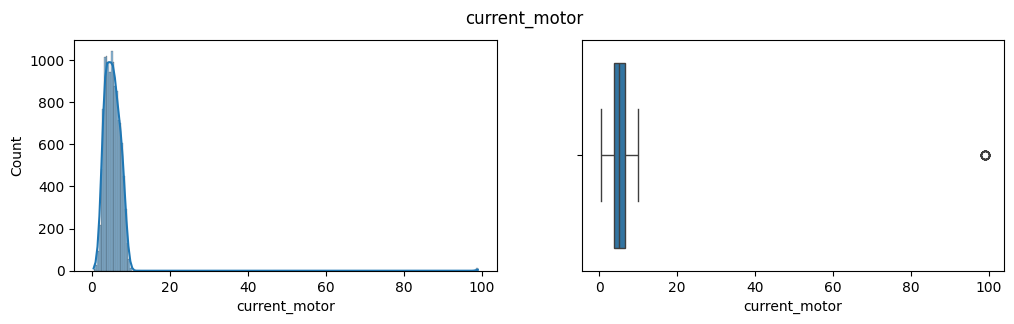

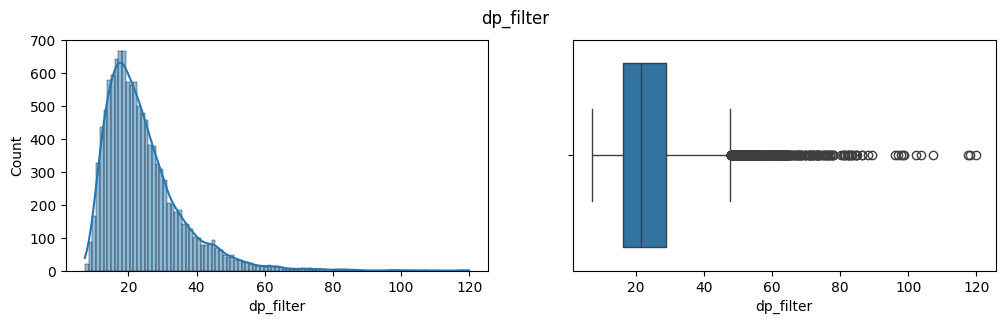

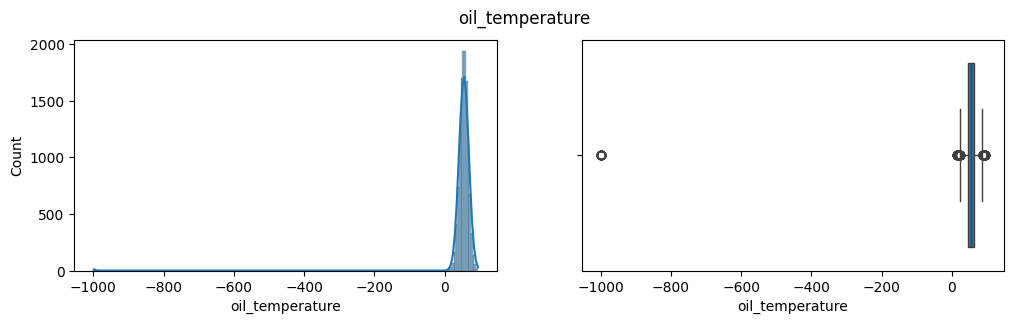

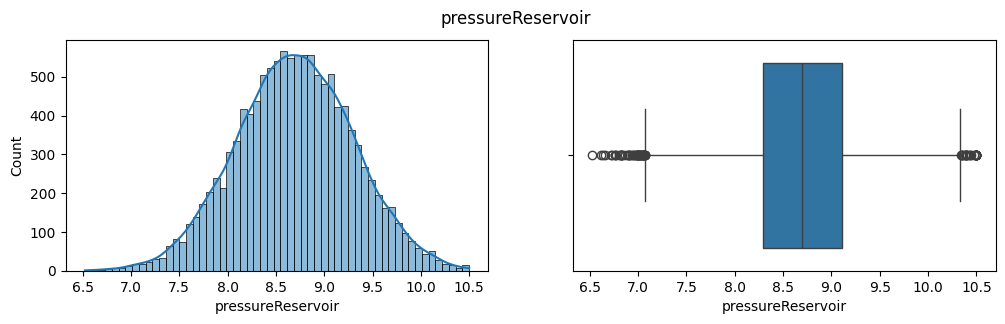

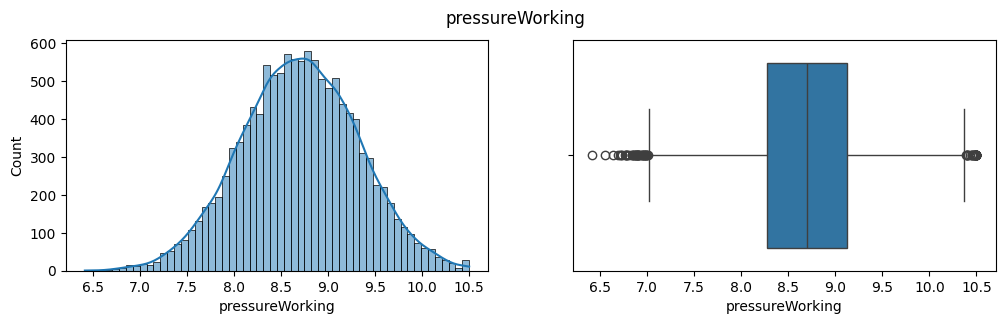

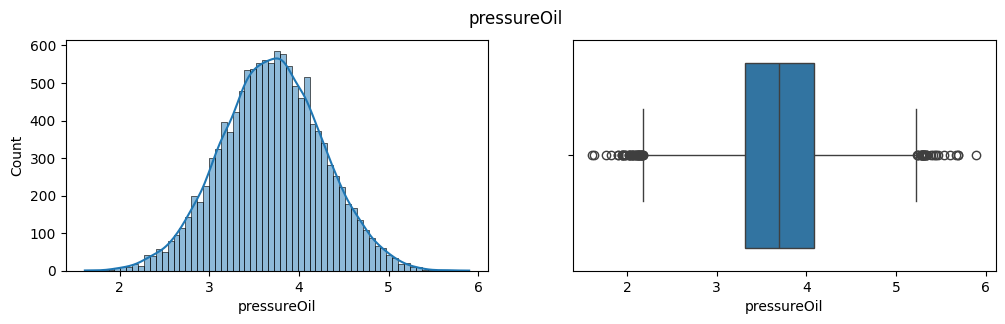

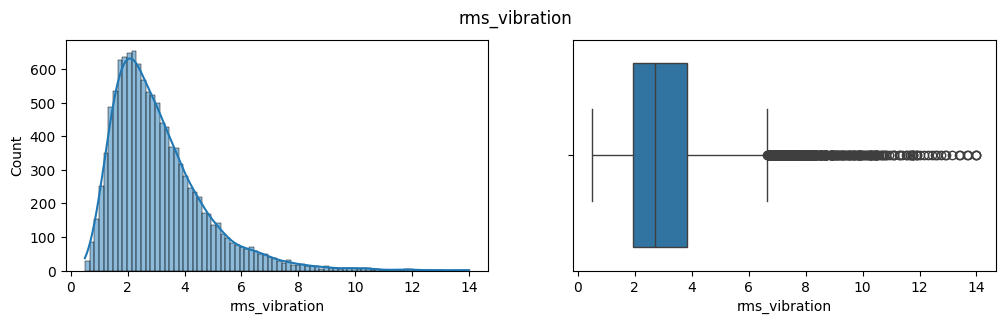

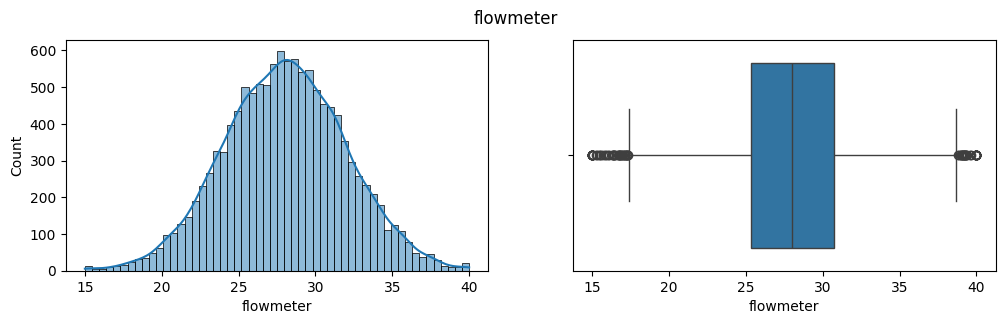

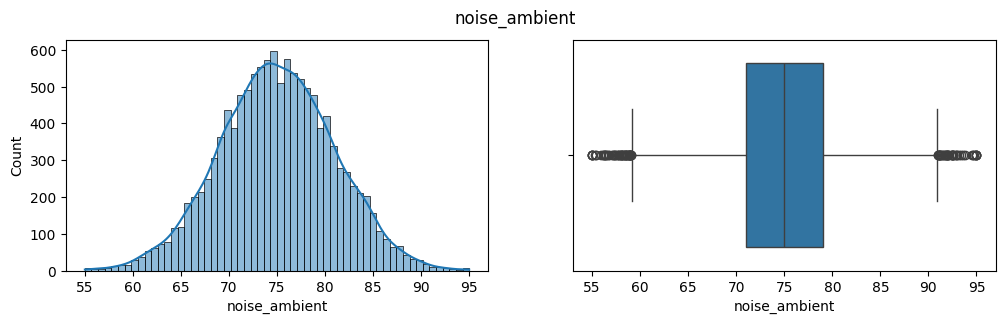

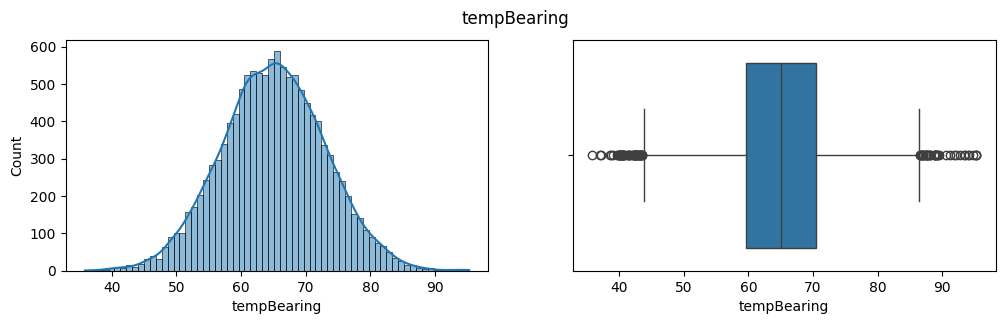

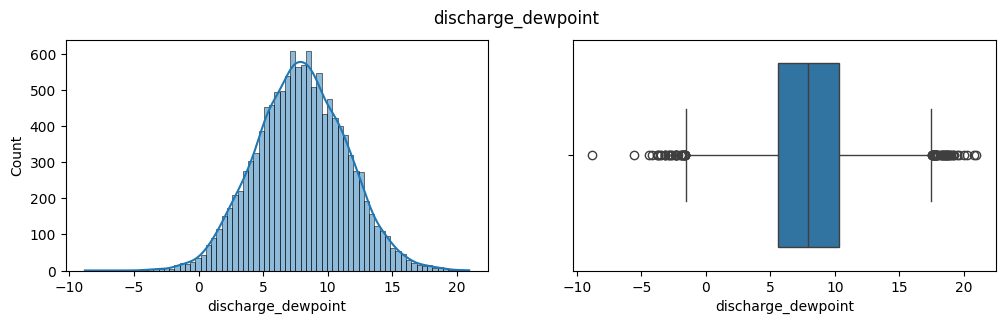

In [8]:
for col in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(readings[col], kde=True, ax=ax[0])
    sns.boxplot(x=readings[col], ax=ax[1])
    fig.suptitle(col)
    plt.show()

**Rozdelenia**

- **Normálne rozdelenie:** tlaky (`pressureReservoir`, `pressureWorking`, `pressureOil`), `flowmeter`, `noise_ambient`, `tempBearing` a `discharge_dewpoint`. `pressureReservoir` a `pressureWorking` majú takmer totožné rozdelenie (priemer 8,698 vs. 8,699; smerodajná odchýlka 0,60 vs. 0,62). Či spolu aj súvisia, overíme koreláciou v časti C.

- **Zošikmené rozdelenie s dlhým chvostom:** `dp_filter` a `rms_vibration` majú v boxplote veľa odľahlých hodnôt na pravej strane. Vysoký tlakový rozdiel na filtri (zanesený filter) aj zvýšené vibrácie môžu byť prejavom opotrebenia. Tieto hodnoty preto nepovažujeme automaticky za chybné, keďže môžu súvisieť s poruchou (`failure`).
- **Nečitateľné grafy:** histogramy `current_motor` a `oil_temperature` sú stlačené na jednu stranu kvôli hodnotám 99 a -999. Ich skutočné rozdelenie zobrazujeme v nasledujúcej bunke bez týchto hodnôt.

current_motor: count=12275, min=0.43, max=10.00, skew=0.178, kurtosis=-0.776


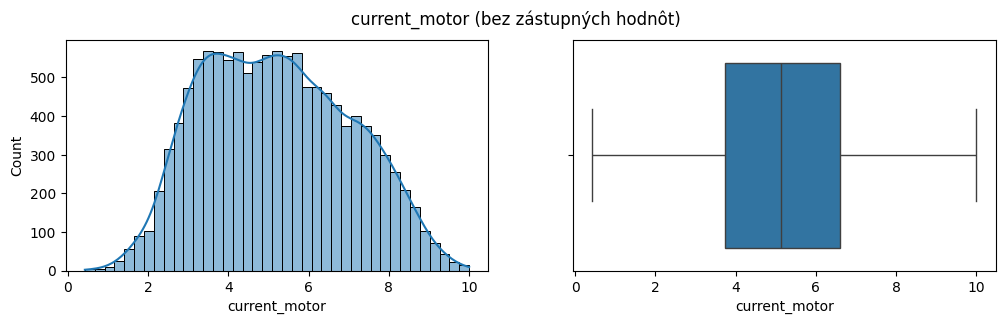

oil_temperature: count=12264, min=15.00, max=95.00, skew=-0.023, kurtosis=-0.010


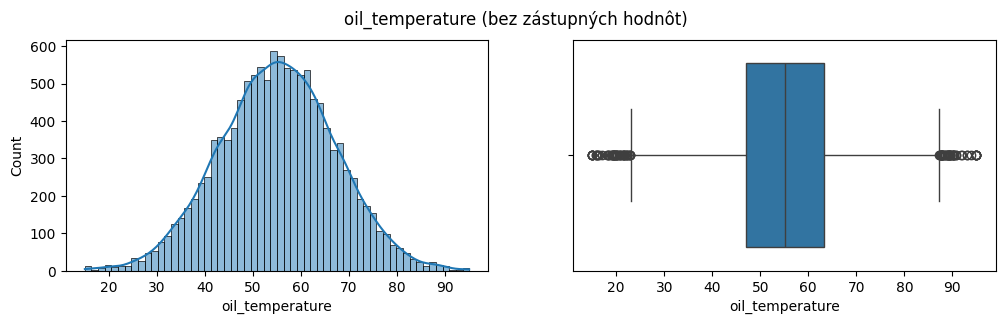

In [9]:
# current_motor and oil_temperature without placeholder values (99, -999)
clean = {'current_motor': readings.loc[readings['current_motor'] != 99, 'current_motor'],
         'oil_temperature': readings.loc[readings['oil_temperature'] != -999, 'oil_temperature']}

for col, s in clean.items():
    print(f'{col}: count={s.count()}, min={s.min():.2f}, max={s.max():.2f}, '
          f'skew={s.skew():.3f}, kurtosis={s.kurtosis():.3f}')
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    sns.histplot(s, kde=True, ax=ax[0])
    sns.boxplot(x=s, ax=ax[1])
    fig.suptitle(f'{col} (bez zástupných hodnôt)')
    plt.show()

**Rozdelenie bez zástupných hodnôt**

- `current_motor` (bez hodnoty 99): rozsah 0,43 - 10,00, šikmosť 0,18, špicatosť -0,78. Rozdelenie je takmer symetrické, ale nie normálne: je plochšie a má dva vrcholy (okolo 3,5 a 5,5).

- `oil_temperature` (bez hodnoty -999): rozsah 15 - 95, šikmosť -0,02, špicatosť -0,01. Rozdelenie je normálne.


Po vynechaní 13 hodnôt (resp. 24) zmiznú extrémne hodnoty šikmosti a špicatosti a grafy sa stanú čitateľnými. Hodnoty **99** a **-999** teda nie sú reálne merania, ale **zástupné hodnoty** (placeholder) pre chýbajúce alebo chybné meranie. V časti 1.2 ich nahradíme za `NaN`.

In [10]:
pd.DataFrame({
    'min': readings[num_cols].min(),
    'count_at_min': [(readings[c] == readings[c].min()).sum() for c in num_cols],
    'max': readings[num_cols].max(),
    'count_at_max': [(readings[c] == readings[c].max()).sum() for c in num_cols],
})

,min,count_at_min,max,count_at_max
current_motor,0.42668,1,99.00000,13
dp_filter,7.22194,1,120.00000,1
oil_temperature,-999.00000,24,95.00000,7
pressureReservoir,6.52408,1,10.50000,11
pressureWorking,6.41603,1,10.50000,18
pressureOil,1.61204,1,5.89799,1
rms_vibration,0.50000,5,14.00000,3
flowmeter,15.00000,11,40.00000,19
noise_ambient,55.00000,3,95.00000,4
tempBearing,35.85349,1,95.26867,1


**Kontrola rozsahu meraných hodnôt**

- **Nereálne (zástupné) hodnoty:** `oil_temperature` = -999 (24x), `current_motor` = 99 (13x).
- **Opakované hraničné hodnoty (orezanie meracím rozsahom senzora):**
  - `flowmeter`: 15 (11x) a 40 (19x)
  - `pressureWorking`: 10,5 (18x), `pressureReservoir`: 10,5 (11x)
  - `oil_temperature`: 95 (7x)
  - `rms_vibration`: 0,5 (5x) a 14 (3x)
  - `noise_ambient`: 55 (3x) a 95 (4x)

  Senzor pravdepodobne nedokáže zmerať hodnotu mimo svojho rozsahu a zapíše hraničnú hodnotu. Skutočná hodnota mohla byť ešte vyššia alebo nižšia.

failure
0    10779
1     1509
Name: count, dtype: int64

failure
0    87.72
1    12.28
Name: proportion, dtype: float64

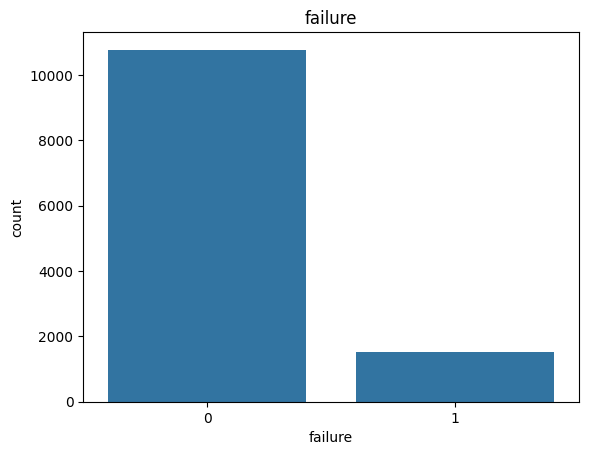

In [11]:
display(readings['failure'].value_counts())
display((readings['failure'].value_counts(normalize=True) * 100).round(2))
sns.countplot(x=readings['failure'])
plt.title('failure')
plt.show()


**Cieľová premenná `failure`**

- Binárna premenná: 0 = bez poruchy (10 779 záznamov, 87,72 %), 1 = porucha (1 509 záznamov, 12,28 %).

In [12]:
print('unique values (raw):          ', units['class_duty'].nunique())
print('unique values (spaces removed):', units['class_duty'].str.strip().nunique())
units['class_duty'].str.strip().value_counts()


unique values (raw):           20
unique values (spaces removed): 10


class_duty
1         270
light     269
L         252
N         192
2         184
heavy     177
normal    173
med       168
3         164
H         151
Name: count, dtype: int64

**Kategorický atribút `class_duty`**

- Pôvodne obsahuje 20 rôznych hodnôt. Po odstránení medzier (napr. ` light` -> `light`) zostane 10.
- Názvy hodnôt naznačujú, že môže ísť len o **3 triedy zaťaženia** zapísané rôznym spôsobom (číslom, skratkou, slovom):
  - ľahké: `1`, `L`, `light`
  - stredné: `2`, `N`, `normal`, `med`
  - ťažké: `3`, `H`, `heavy`
- Ide však iba o predpoklad založený na názvoch.

## Párová analýza atribútov (C)
Skúmame vzťahy medzi dvojicami numerických atribútov pomocou korelačnej matice (Pearson aj Spearman) a bodových grafov.
Pre analýzu používame kópiu dát `eda`, v ktorej sú zástupné hodnoty (99, -999) nahradené za `NaN`, aby neskresľovali korelácie. Pôvodný `readings` zostáva nezmenený.

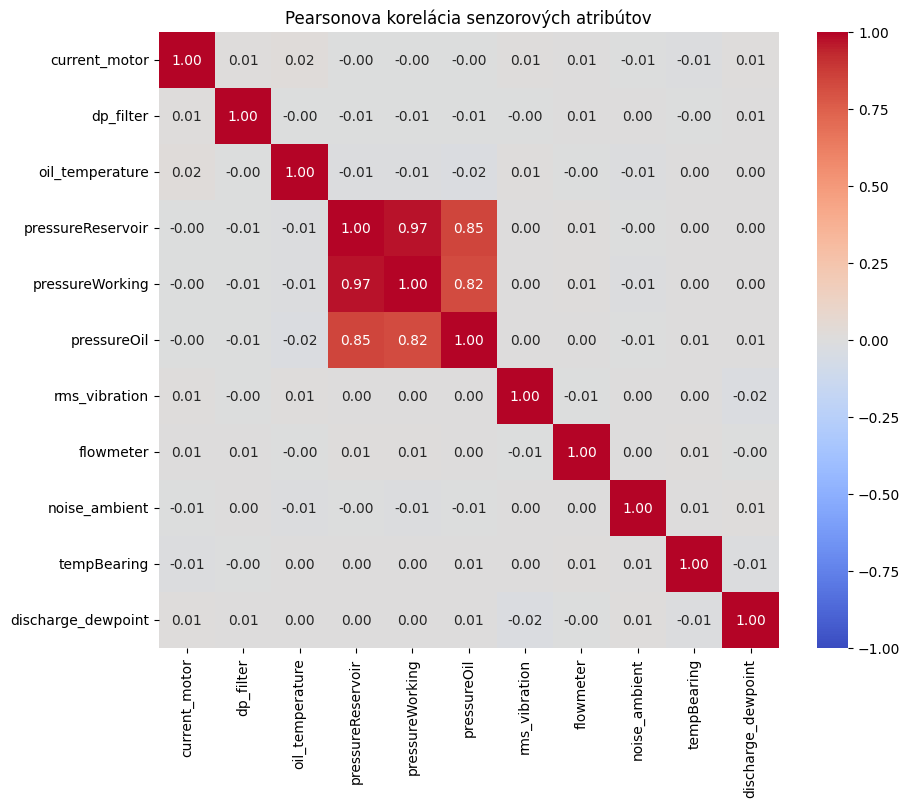

In [13]:
# copy for pair analysis: placeholder values (99, -999) replaced by NaN,
eda = readings.copy()
eda.loc[eda['current_motor'] == 99, 'current_motor'] = np.nan
eda.loc[eda['oil_temperature'] == -999, 'oil_temperature'] = np.nan

plt.figure(figsize=(10, 8))
sns.heatmap(eda[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearsonova korelácia senzorových atribútov')
plt.show()


In [14]:
# strongest pairs - Pearson (linear) vs. Spearman (rank-based)
pearson = eda[num_cols].corr()
spearman = eda[num_cols].corr(method='spearman')
mask = np.triu(np.ones(pearson.shape, dtype=bool), k=1)
pairs = pd.DataFrame({'pearson': pearson.where(mask).stack(),
                      'spearman': spearman.where(mask).stack()})
pairs.sort_values('pearson', key=abs, ascending=False).head(8).round(3)


pearson  spearman
pressureReservoir pressureWorking       0.970     0.968
                  pressureOil           0.848     0.838
pressureWorking   pressureOil           0.822     0.810
rms_vibration     discharge_dewpoint   -0.023    -0.024
oil_temperature   pressureOil          -0.021    -0.022
current_motor     oil_temperature       0.017     0.013
                  rms_vibration         0.014     0.018
oil_temperature   pressureReservoir    -0.014    -0.013

**Korelácia**

- **Silne korelovaná skupina tlakov:**
  - `pressureReservoir` - `pressureWorking`: r = 0,97 (takmer lineárna závislosť)
  - `pressureReservoir` - `pressureOil`: r = 0,85
  - `pressureWorking` - `pressureOil`: r = 0,82
- **Ostatné dvojice** sú prakticky nekorelované (|r| <= 0,02). Medzi ostatnými senzormi teda nie je lineárny ani monotónny vzťah.
- **Pearson vs. Spearman:** oba koeficienty sú takmer zhodné, takže vzťahy medzi tlakmi sú lineárne a nespôsobujú ich odľahlé hodnoty.
- **Dôsledok pre modelovanie:** tri tlakové atribúty nesú z veľkej časti rovnakú informáciu. Pri niektorých modeloch môže byť vhodné ponechať iba jeden z nich alebo ich skombinovať.

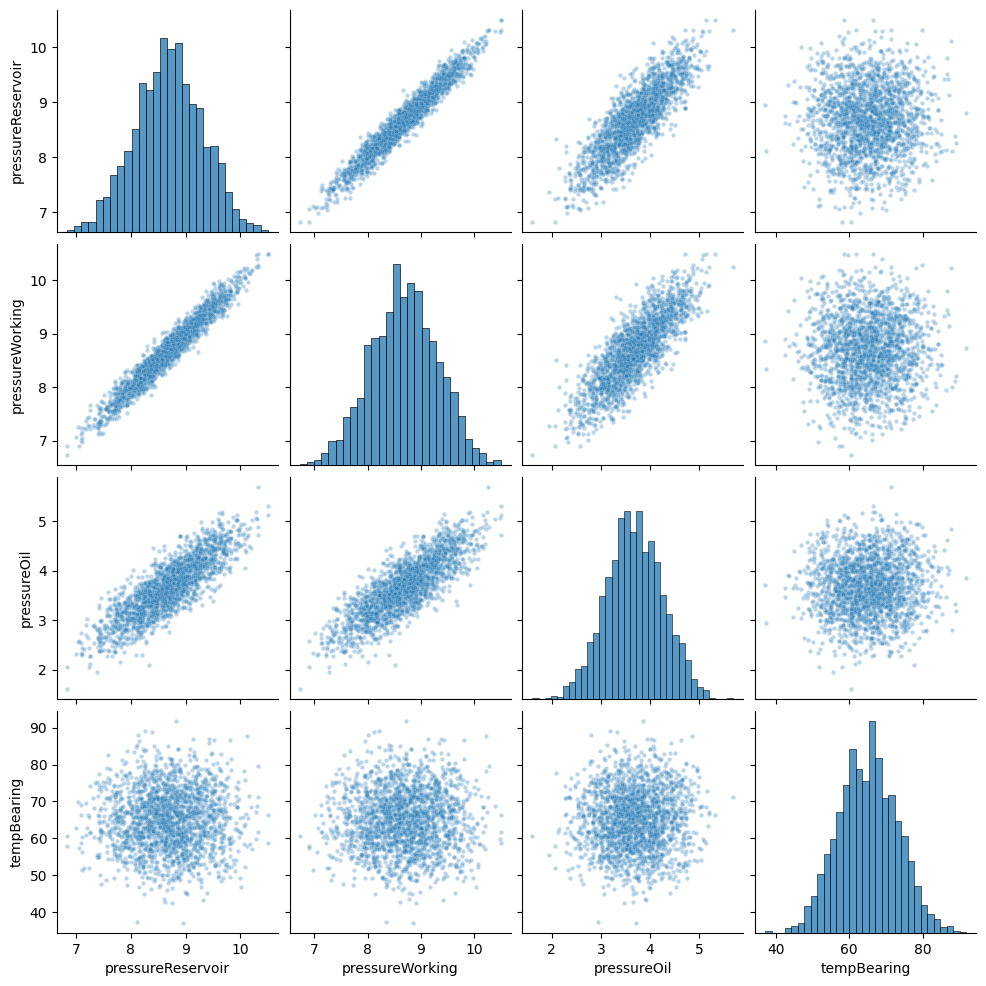

In [15]:
sns.pairplot(eda[['pressureReservoir', 'pressureWorking', 'pressureOil', 'tempBearing']].sample(2000, random_state=1),
             plot_kws={'alpha': 0.3, 's': 10})
plt.show()


**Bodové grafy**

Na vzorke 2 000 záznamov vidno, že dvojice tlakov tvoria úzke pretiahnuté skupiny bodov pozdĺž diagonály. Najužšie je pri `pressureReservoir` - `pressureWorking`, čo zodpovedá lineárnej závislosti. Pre porovnanie, `tempBearing` tvorí s každým tlakom okrúhle skupiny bez akéhokoľvek trendu.


corr yearCommission x hours_service: -0.993


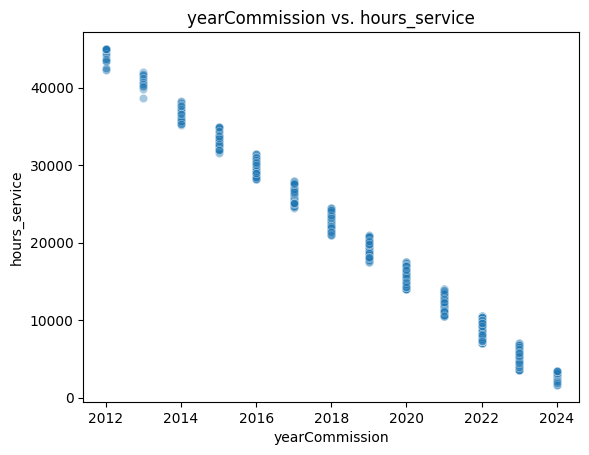

In [16]:
# numeric attributes in units
print('corr yearCommission x hours_service:', units['yearCommission'].corr(units['hours_service']).round(3))
sns.scatterplot(data=units, x='yearCommission', y='hours_service', alpha=0.4)
plt.title('yearCommission vs. hours_service')
plt.show()


**`units`: `yearCommission` - `hours_service`**

- Korelácia r = -0,993: čím skôr bola jednotka uvedená do prevádzky, tým viac prevádzkových hodín má. V grafe tvorí každý rok úzke pásmo hodnôt.
- Oba atribúty nesú takmer rovnakú informáciu (vek jednotky), preto sú pre model redundantné.
- Vďaka tejto závislosti je možné 100 chýbajúcich hodnôt `hours_service` (zistených v časti A) spoľahlivo odhadnúť z `yearCommission`.


## Závislosť predikovanej premennej `failure` od ostatných atribútov (D)
Skúmame, ktoré atribúty sa líšia medzi meraniami bez poruchy (0) a s poruchou (1): pomocou korelácie s `failure`, porovnania mediánov, boxplotov, chýbajúcich hodnôt a atribútov jednotky zo súboru `units`.

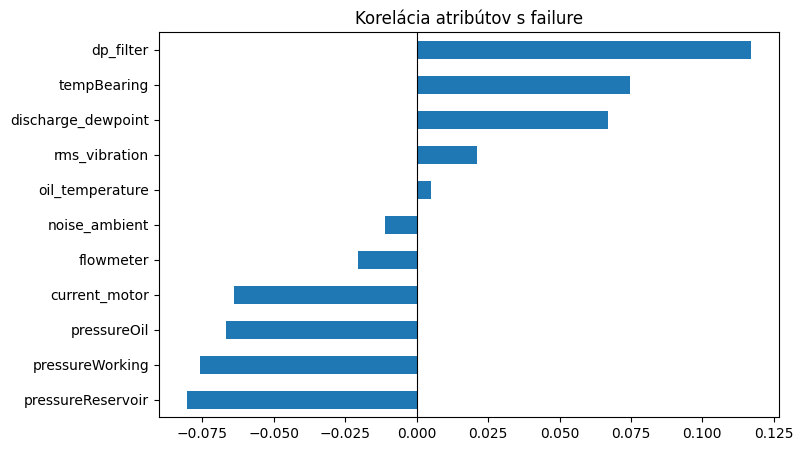

failure,0,1,difference
current_motor,5.20,4.61,-0.59
dp_filter,21.34,24.80,3.45
oil_temperature,55.11,55.28,0.17
pressureReservoir,8.72,8.56,-0.16
pressureWorking,8.72,8.57,-0.15
pressureOil,3.72,3.58,-0.13
rms_vibration,2.71,2.76,0.04
flowmeter,28.04,27.88,-0.16
noise_ambient,74.98,74.68,-0.30
tempBearing,64.81,66.41,1.59


pressureReservoir    -0.080
pressureWorking      -0.076
pressureOil          -0.067
current_motor        -0.064
flowmeter            -0.020
noise_ambient        -0.011
oil_temperature       0.005
rms_vibration         0.021
discharge_dewpoint    0.067
tempBearing           0.075
dp_filter             0.117
Name: failure, dtype: float64

In [17]:
fail_corr = eda[num_cols + ['failure']].corr()['failure'].drop('failure').sort_values()
fail_corr.plot(kind='barh', figsize=(8, 5), title='Korelácia atribútov s failure')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

med = eda.groupby('failure')[num_cols].median().T
med['difference'] = med[1] - med[0]
display(med.round(2))
display(fail_corr.round(3))

**Korelácia a mediány**

- **Žiadny atribút nemá silný vzťah k `failure`.** Najvyššia korelácia je len r = 0,12 (`dp_filter`).
- **Vyššie hodnoty pri poruche:** `dp_filter` (medián +3,45), `tempBearing` (+1,59), `discharge_dewpoint` (+0,84).
- **Nižšie hodnoty pri poruche:** `current_motor` (-0,59) a všetky tri tlaky (-0,13 až -0,16). Tlaky majú voči `failure` podobnú koreláciu (-0,07 až -0,08), čo zodpovedá ich vzájomnej závislosti z časti C.
- **Prakticky bez vzťahu:** `oil_temperature`, `noise_ambient`, `flowmeter` a `rms_vibration` (|r| <= 0,021).

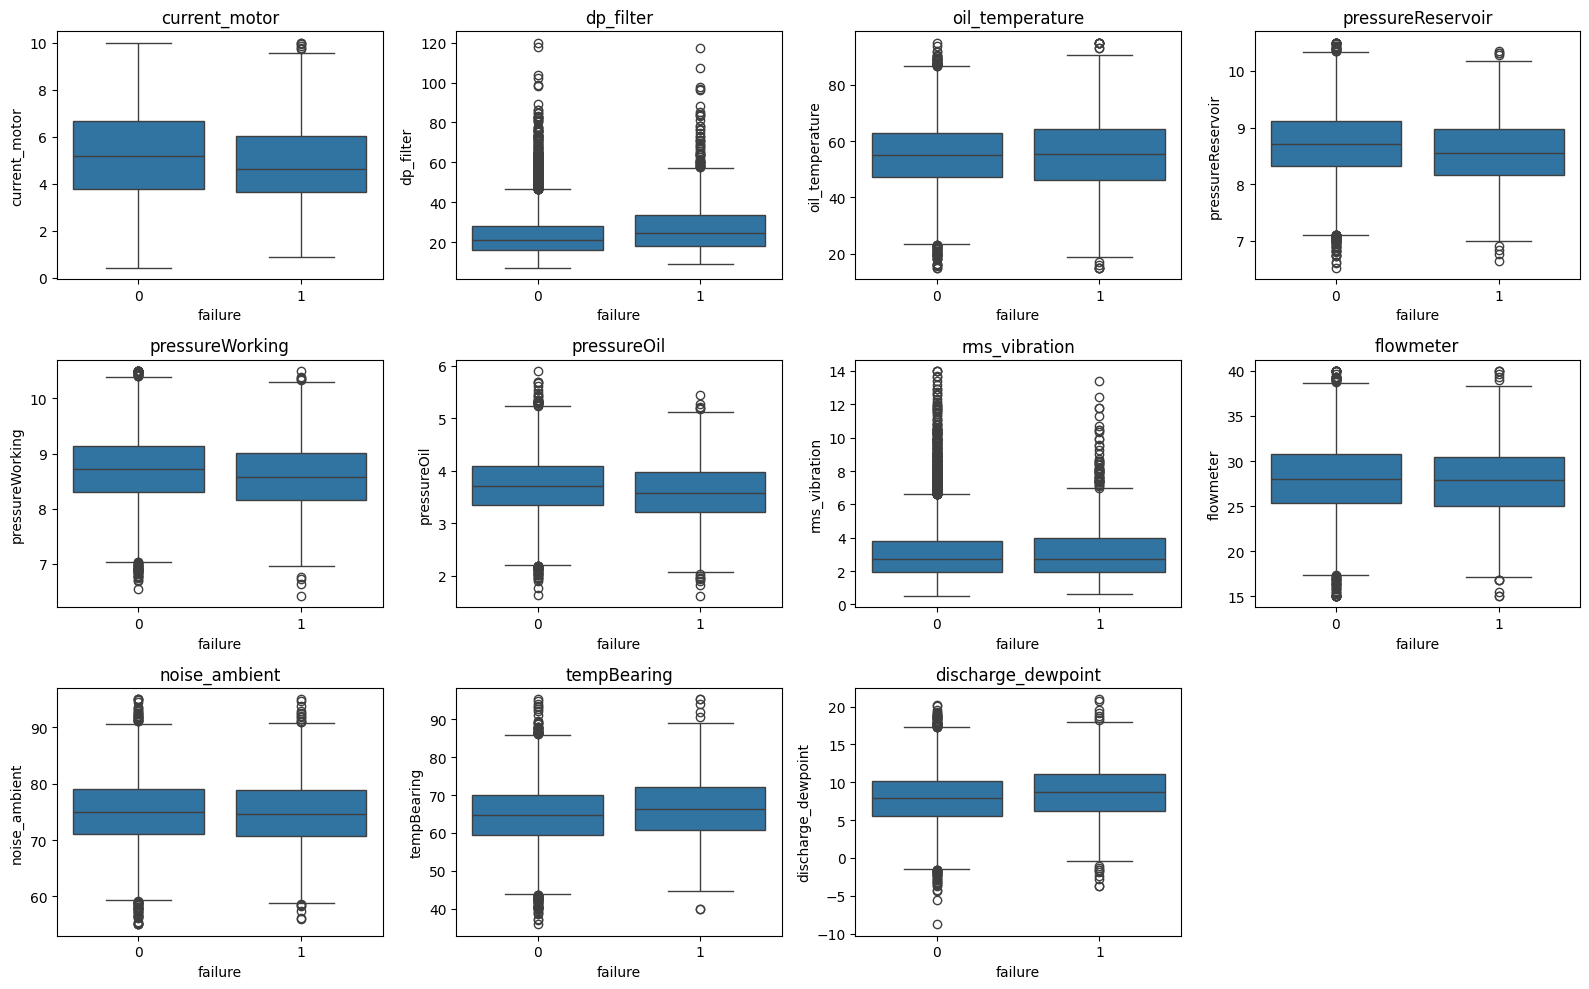

In [18]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=eda, x='failure', y=col, ax=ax)
    ax.set_title(col)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()


**Boxploty podľa `failure`**

Posuny zistené pri mediánoch sú viditeľné aj v boxplotoch: pri poruche je vyšší `dp_filter`, `tempBearing` a `discharge_dewpoint`, nižší `current_motor` a tlaky. Boxy oboch skupín sa však vo všetkých prípadoch výrazne prekrývajú. Žiadny atribút sám o sebe teda neoddelí poruchy od bežnej prevádzky. Model bude musieť kombinovať viacero atribútov.


In [19]:
for col in ['dp_filter', 'rms_vibration']:
    rate = (readings.groupby(readings[col].isna())['failure'].mean() * 100).round(2)
    print(f'{col}: failure rate if value present = {rate[False]} %, if missing = {rate[True]} %')


dp_filter: failure rate if value present = 10.42 %, if missing = 57.17 %
rms_vibration: failure rate if value present = 10.46 %, if missing = 57.72 %


**Chýbajúce hodnoty a `failure`**

| Atribút | Podiel porúch (hodnota je) | Podiel porúch (hodnota chýba) |
|---|---|---|
| `dp_filter` | 10,42 % | 57,17 % |
| `rms_vibration` | 10,46 % | 57,72 % |

Ak hodnota chýba, porucha nastáva **približne 5,5-krát častejšie**. Chýbanie hodnoty nie je náhodné: samotný fakt, že senzor nič nezaznamenal, silne súvisí s poruchou a je silnejším signálom ako ktorýkoľvek senzor.

In [20]:
merged = eda.assign(unit_num=eda['unitId'].str.extract(r'(\d+)')[0].astype(int)) \
            .merge(units, left_on='unit_num', right_on='unitId', suffixes=('', '_unit'))
merged['class_duty'] = merged['class_duty'].str.strip()
print('merged rows:', len(merged))

# failure rate % per class_duty value
(merged.groupby('class_duty')['failure'].mean() * 100).round(2).sort_values()


merged rows: 12156


class_duty
heavy      5.78
H          6.71
3          8.40
normal     8.51
N          8.71
med       10.33
2         10.41
L         17.16
light     18.75
1         18.84
Name: failure, dtype: float64

**`class_duty` a `failure`**

Na analýzu sme dočasne spojili `readings` s `units` cez `unitId`. Spojených je 12 156 záznamov, čo je 12 288 mínus 132 meraní bez zodpovedajúcej jednotky z časti A.

- Varianty ľahkej triedy (`1`, `L`, `light`) majú podiel porúch 17,2 - 18,8 %, čo je zreteľne viac ako ostatné hodnoty (5,8 - 10,4 %).
- Zvyšné hodnoty majú podobný podiel porúch; najnižší majú `heavy` (5,8 %) a `H` (6,7 %).
- Tým sa potvrdzuje predpoklad z časti B, že `1`, `L` a `light` označujú tú istú triedu. Hranica medzi strednou a ťažkou triedou je menej zreteľná (`3` = 8,40 % vs. `normal` = 8,51 %).
- Zaujímavé je, že jednotky s ľahkým zaťažením majú poruchy najčastejšie.

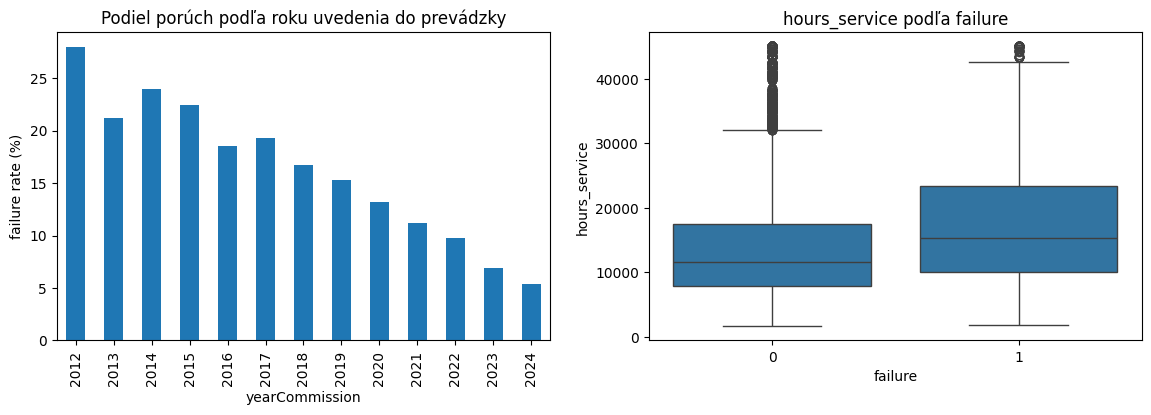

median hours_service: {0: 11543.4, 1: 15410.5}
corr with failure: {'hours_service': 0.143, 'yearCommission': -0.14}


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(merged.groupby('yearCommission')['failure'].mean() * 100).plot(kind='bar', ax=ax[0])
ax[0].set_ylabel('failure rate (%)')
ax[0].set_title('Podiel porúch podľa roku uvedenia do prevádzky')
sns.boxplot(data=merged, x='failure', y='hours_service', ax=ax[1])
ax[1].set_title('hours_service podľa failure')
plt.show()

print('median hours_service:', merged.groupby('failure')['hours_service'].median().to_dict())
print('corr with failure:', merged[['hours_service', 'yearCommission', 'failure']].corr()['failure'].drop('failure').round(3).to_dict())


**Vek jednotky a `failure`**

- **`yearCommission`:** podiel porúch s rokom uvedenia do prevádzky klesá, z približne 28 % (2012) na približne 5 % (2024). Staršie jednotky sa kazia častejšie.
- **`hours_service`:** jednotky s poruchou majú medián 15 410 hodín, bez poruchy 11 543 hodín.
- Korelácia s `failure` je r = 0,143 (`hours_service`) a r = -0,14 (`yearCommission`), teda vyššia ako pri ktoromkoľvek senzore. Oba atribúty opisujú to isté, t. j. vek jednotky (časť C).
- **Záver:** atribúty zo súboru `units` obsahujú užitočnú informáciu pre predikciu. Spojenie `readings` s `units` je preto opodstatnené.


## Prvotné zamyslenie k riešeniu (E)

**Sú niektoré atribúty medzi sebou závislé?**
- Áno, tri tlakové atribúty tvoria silne korelovanú skupinu: `pressureReservoir` - `pressureWorking` (r = 0,97), `pressureReservoir` - `pressureOil` (r = 0,85), `pressureWorking` - `pressureOil` (r = 0,82). Nesú z veľkej časti rovnakú informáciu.
- V súbore `units` sú takmer úplne závislé `yearCommission` a `hours_service` (r = −0,993). Oba opisujú vek jednotky.
- Ostatné senzorové atribúty navzájom nekorelujú (|r| ≤ 0,02).

**Od ktorých atribútov závisí predikovaná premenná `failure`?**
- Žiadny senzor nemá k `failure` silný vzťah (najvyššie r = 0,12 pri `dp_filter`). Pri poruche sú vyššie `dp_filter`, `tempBearing` a `discharge_dewpoint` a nižšie `current_motor` a tlaky. Rozdelenia oboch skupín sa však výrazne prekrývajú, preto bude model musieť kombinovať viacero atribútov.
- Najsilnejším signálom je **chýbajúca hodnota** `dp_filter` alebo `rms_vibration`: podiel porúch je vtedy približne 57 % namiesto približne 10 %.
- Silnejší vzťah ako senzory má aj **vek jednotky**: podiel porúch klesá z približne 28 % (2012) na približne 5 % (2024) a korelácia s `failure` je r = 0,143 (`hours_service`), resp. −0,14 (`yearCommission`).
- Varianty ľahkej triedy `class_duty` (`1`, `L`, `light`) majú podiel porúch 17,2 - 18,8 %, ostatné hodnoty 5,8 - 10,4 %.

**Je potrebné kombinovať záznamy z viacerých súborov?**
- Áno. Cieľová premenná je iba v `readings`, no atribúty jednotky zo súboru `units` (vek, `class_duty`) súvisia s `failure` viac ako ktorýkoľvek senzor. Súbory je potrebné spojiť cez `unitId`, ktorého formát treba najprv zjednotiť. 132 meraní nemá v `units` zodpovedajúcu jednotku.
- Súbor `gateways` je s jednotkami prepojený vzťahom 1:1, ale jednotke je priradených iba 2 000 zo 16 000 brán. Vzťah jeho atribútov k `failure` sme v časti 1.1 neskúmali.

**Ďalšie dôsledky pre riešenie**
- Triedy `failure` sú nevyvážené (12,28 % porúch). Pri trénovaní bude potrebné stratifikované delenie dát a metriky ako recall či F1-skóre namiesto presnosti (accuracy).
- Zástupné hodnoty (−999, 99), duplicity, nejednotné formáty dátumov a nekonzistentný zápis `class_duty` je potrebné vyriešiť v časti 1.2.
- Pre jednu jednotku existuje v priemere približne 6 meraní. Pri delení na trénovaciu a testovaciu množinu by merania tej istej jednotky nemali byť v oboch množinách naraz.


# 1.2 Identifikácia problémov, integrácia a čistenie dát

V tejto časti sa zameriame na identifikáciu problémov v dátach a ich následné riešenie. Skontrolujeme najmä duplicitné a chýbajúce hodnoty, nejednotné formáty, abnormálne a nelogické hodnoty. Následne dáta vhodne vyčistíme a pripravíme na ďalšie spracovanie.

## A) Identifikácia a prvotné riešenie problémov

Najskôr skontrolujeme výskyt duplicitných záznamov v jednotlivých dátových súboroch. Duplicitné záznamy môžu skresľovať výsledky analýzy, preto je potrebné zistiť ich počet a následne rozhodnúť o ich odstránení.

### Duplicitné záznamy

In [22]:
readings = pd.read_csv('174/readings.csv', sep='\t')
units    = pd.read_csv('174/units.csv', sep=',')
gateways = pd.read_csv('174/gateways.csv', sep=';')

data = {'readings': readings, 'units': units, 'gateways': gateways}

In [23]:
print("readings:", readings.duplicated().sum())
print("units:", units.duplicated().sum())
print("gateways:", gateways.duplicated().sum())

readings: 182
units: 0
gateways: 0


V súbore `readings` bolo identifikovaných **182 duplicitných záznamov**. V súboroch `units` a `gateways` sa duplicitné záznamy nenachádzajú. Keďže ide o úplne zhodné záznamy, duplicity v `readings` odstránime, aby zbytočne neovplyvňovali ďalšiu analýzu.

In [24]:
readings = readings.drop_duplicates()

print("Počet záznamov po odstránení duplicít:", len(readings))
print("Počet zostávajúcich duplicít:", readings.duplicated().sum())

Počet záznamov po odstránení duplicít: 12106
Počet zostávajúcich duplicít: 0


### Chýbajúce hodnoty

Ďalším kontrolovaným problémom sú chýbajúce hodnoty. Pre každý dátový súbor zistíme počet chýbajúcich hodnôt v jednotlivých atribútoch. Na základe ich výskytu následne rozhodneme o vhodnom spôsobe ich spracovania.

In [25]:
data['readings'] = readings

for name, df in data.items():
    print(f"\n{name}:")
    print(df.isnull().sum())


readings:
unitId                  0
cycleTs                 0
current_motor           0
dp_filter             480
oil_temperature         0
pressureReservoir       0
pressureWorking         0
pressureOil             0
rms_vibration         466
flowmeter               0
noise_ambient           0
tempBearing             0
discharge_dewpoint      0
failure                 0
dtype: int64

units:
number_serial       0
yearCommission      0
ownerOperator       0
unitId              0
manufacturer        0
class_duty          0
idDepot             0
install_region      0
code_line           0
codeModel           0
last_overhaul       0
hours_service     100
dtype: int64

gateways:
firmware_version        0
Vendor                  0
idGateway               0
Technician              0
Lon                     0
seenLast                0
hardware_model          0
Lat                     0
date_install            0
Ipv4                    0
idDepot                 0
unitId              14000
mac_

Z kontroly chýbajúcich hodnôt vyplýva, že v súbore `readings` chýba 480 hodnôt atribútu `dp_filter` a 466 hodnôt atribútu `rms_vibration`. V súbore `units` chýba 100 hodnôt `hours_service`. Najväčší počet chýbajúcich hodnôt sa nachádza v súbore `gateways`, kde atribút `unitId` obsahuje 14 000 chýbajúcich hodnôt.

Pred samotným čistením je potrebné zistiť, akú časť jednotlivých dát predstavujú chýbajúce hodnoty a podľa toho zvoliť vhodný spôsob ich spracovania.

In [26]:
for name, df in data.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    
    for column, count in missing.items():
        percent = count / len(df) * 100
        print(f"{name} - {column}: {count} ({percent:.2f} %)")

readings - dp_filter: 480 (3.96 %)
readings - rms_vibration: 466 (3.85 %)
units - hours_service: 100 (5.00 %)
gateways - unitId: 14000 (87.50 %)


Chýbajúce hodnoty v atribútoch `dp_filter`, `rms_vibration` a `hours_service` predstavujú približne 4-5 % záznamov. Keďže ide o numerické atribúty a nechceme zbytočne odstrániť celé záznamy, chýbajúce hodnoty nahradíme mediánom príslušného atribútu. Medián je vhodný aj vzhľadom na možný výskyt vychýlených hodnôt, pretože je voči nim odolnejší ako priemer.
Pri `hours_service` použijeme medián jednotiek s rovnakým rokom uvedenia do prevádzky, keďže podľa časti 1.1 C je `hours_service` takmer úplne závislý od `yearCommission` (r = −0,993).

V atribúte `unitId` súboru `gateways` chýba 87,5 % hodnôt. Ako overíme v časti o integrácii súboru gateways, zostávajúcich 2 000 záznamov obsahuje 2 000 unikátnych `unitId` a zároveň 2 000 unikátnych `idGateway`. Tieto záznamy teda poskytujú jednoznačné mapovanie medzi jednotkou a bránou.

Chýbajúce `unitId` preto nebudeme dopĺňať. Na integráciu využijeme iba záznamy s dostupným `unitId`.

In [27]:
readings['dp_filter_missing'] = readings['dp_filter'].isna().astype(int)
readings['rms_vibration_missing'] = readings['rms_vibration'].isna().astype(int)

print(readings['dp_filter_missing'].value_counts())
print()
print(readings['rms_vibration_missing'].value_counts())

dp_filter_missing
0    11626
1      480
Name: count, dtype: int64

rms_vibration_missing
0    11640
1      466
Name: count, dtype: int64


In [28]:
print("dp_filter:")
print(pd.crosstab(
    readings['dp_filter_missing'],
    readings['failure'],
    normalize='index'
) * 100)

print("\nrms_vibration:")
print(pd.crosstab(
    readings['rms_vibration_missing'],
    readings['failure'],
    normalize='index'
) * 100)

dp_filter:
failure                    0          1
dp_filter_missing                      
0                  89.592293  10.407707
1                  42.500000  57.500000

rms_vibration:
failure                        0          1
rms_vibration_missing                      
0                      89.570447  10.429553
1                      41.630901  58.369099


Analýza ukázala, že chýbajúce hodnoty v atribútoch `dp_filter` a `rms_vibration` nie sú náhodné. Pri záznamoch bez chýbajúcej hodnoty je podiel porúch približne 10 %, zatiaľ čo pri chýbajúcej hodnote dosahuje 57,5 % (dp_filter), resp. 58,4 % (rms_vibration).

Samotná informácia o chýbajúcej hodnote teda môže byť užitočná pri predikcii `failure`. Pred doplnením chýbajúcich hodnôt preto vytvoríme pomocné binárne atribúty `dp_filter_missing` a `rms_vibration_missing`, ktoré zachovajú informáciu o tom, či hodnota pôvodne chýbala.

Chýbajúce numerické hodnoty následne doplníme mediánom. Tým zachováme všetky záznamy a zároveň nestratíme informáciu o pôvodnom výskyte chýbajúcej hodnoty.

In [29]:
readings['dp_filter'] = readings['dp_filter'].fillna(readings['dp_filter'].median())
readings['rms_vibration'] = readings['rms_vibration'].fillna(readings['rms_vibration'].median())

units['hours_service'] = units['hours_service'].fillna(
    units.groupby('yearCommission')['hours_service'].transform('median')
)

In [30]:
print("dp_filter:", readings['dp_filter'].isnull().sum())
print("rms_vibration:", readings['rms_vibration'].isnull().sum())
print("hours_service:", units['hours_service'].isnull().sum())

dp_filter: 0
rms_vibration: 0
hours_service: 0


### Nekonzistentné a chybné hodnoty

Okrem chýbajúcich hodnôt skontrolujeme aj výskyt nekonzistentných alebo podozrivých hodnôt. Pri kategorických atribútoch skontrolujeme jednotlivé unikátne hodnoty a pri numerických atribútoch ich minimálne a maximálne hodnoty. Cieľom je identifikovať hodnoty, ktoré môžu byť dôsledkom nesprávneho zápisu alebo zberu dát.

In [31]:
print(units['class_duty'].value_counts(dropna=False))

class_duty
1           247
light       238
L           224
N           171
2           164
heavy       161
normal      156
med         154
3           146
H           140
 light       31
 L           28
 1           23
 N           21
 2           20
 3           18
 normal      17
 heavy       16
 med         14
 H           11
Name: count, dtype: int64


In [32]:
numeric_cols = readings.select_dtypes(include=np.number).columns

for col in numeric_cols:
    print(f"{col}: min = {readings[col].min()}, max = {readings[col].max()}")

current_motor: min = 0.42668, max = 99.0
dp_filter: min = 7.22194, max = 120.0
oil_temperature: min = -999.0, max = 95.0
pressureReservoir: min = 6.52408, max = 10.5
pressureWorking: min = 6.41603, max = 10.5
pressureOil: min = 1.61204, max = 5.89799
rms_vibration: min = 0.5, max = 14.0
flowmeter: min = 15.0, max = 40.0
noise_ambient: min = 55.0, max = 95.0
tempBearing: min = 35.85349, max = 95.26867
discharge_dewpoint: min = -8.80389, max = 20.95943
failure: min = 0, max = 1
dp_filter_missing: min = 0, max = 1
rms_vibration_missing: min = 0, max = 1


Z kontroly atribútu `class_duty` je viditeľný nejednotný zápis hodnôt. Niektoré kategórie sa v dátach nachádzajú viackrát kvôli medzere na začiatku hodnoty, napr. `light` a ` light`, `L` a ` L`. Tieto nadbytočné medzery odstránime, aby rovnaké kategórie neboli považované za rozdielne hodnoty.

In [33]:
units['class_duty'] = units['class_duty'].str.strip()

print(units['class_duty'].value_counts())

class_duty
1         270
light     269
L         252
N         192
2         184
heavy     177
normal    173
med       168
3         164
H         151
Name: count, dtype: int64


Po odstránení nadbytočných medzier zostáva v atribúte `class_duty` viacero rôznych označení kategórií. Pred ich prípadným zjednotením sme v časti 1.1 D overili, či jednotlivé označenia vykazujú podobný vzťah k predikovanej premennej `failure`. Kategórie nebudeme spájať iba na základe predpokladu o ich význame.

Analýza v časti 1.1 D ukázala, že jednotlivé označenia `class_duty` majú rozdielny podiel porúch. Hoci niektoré názvy môžu naznačovať rovnaký význam (napr. `light`, `L` a `1`), z dostupných dát nie je možné jednoznačne určiť správne mapovanie všetkých kategórií.

Najmä kategória `3` nevykazuje podobný podiel porúch ako `heavy` a `H`, preto by jej automatické zaradenie do tejto skupiny nebolo dostatočne podložené. Z tohto dôvodu odstránime iba nadbytočné medzery v názvoch a ostatné kategórie ponecháme samostatné.

Pri kontrole rozsahov numerických atribútov boli identifikované podozrivé hodnoty. Atribút `current_motor` dosahuje hodnotu 99 a `oil_temperature` hodnotu -999. Tieto hodnoty výrazne vybočujú z ostatných meraní a môžu predstavovať chybové alebo zástupné hodnoty. Pred ich úpravou skontrolujeme ich počet a porovnáme ich s ostatnými hodnotami daných atribútov.

In [34]:
print("current_motor = 99:", (readings['current_motor'] == 99).sum())
print("oil_temperature = -999:", (readings['oil_temperature'] == -999).sum())

print("\ncurrent_motor:")
print(readings['current_motor'].describe())

print("\noil_temperature:")
print(readings['oil_temperature'].describe())

current_motor = 99: 13
oil_temperature = -999: 24

current_motor:
count    12106.000000
mean         5.310149
std          3.570578
min          0.426680
25%          3.737015
50%          5.123275
75%          6.593510
max         99.000000
Name: current_motor, dtype: float64

oil_temperature:
count    12106.000000
mean        53.019552
std         48.391812
min       -999.000000
25%         47.072845
50%         55.119715
75%         63.155635
max         95.000000
Name: oil_temperature, dtype: float64


Hodnota `99` sa v atribúte `current_motor` nachádza 13-krát, pričom 75 % hodnôt je nižších ako približne 6,59. Hodnota `-999` sa v atribúte `oil_temperature` nachádza 24-krát a výrazne sa odlišuje od bežného rozsahu nameraných teplôt. Tieto hodnoty preto považujeme za chybové alebo zástupné hodnoty.

Keďže ide iba o malý počet záznamov, chybné hodnoty najskôr nahradíme za chýbajúce hodnoty a následne ich doplníme mediánom príslušného atribútu.

In [35]:
readings['current_motor'] = readings['current_motor'].replace(99, np.nan)
readings['oil_temperature'] = readings['oil_temperature'].replace(-999, np.nan)

readings['current_motor'] = readings['current_motor'].fillna(readings['current_motor'].median())
readings['oil_temperature'] = readings['oil_temperature'].fillna(readings['oil_temperature'].median())

In [36]:
print("current_motor = 99:", (readings['current_motor'] == 99).sum())
print("oil_temperature = -999:", (readings['oil_temperature'] == -999).sum())

print("Chýbajúce current_motor:", readings['current_motor'].isnull().sum())
print("Chýbajúce oil_temperature:", readings['oil_temperature'].isnull().sum())

current_motor = 99: 0
oil_temperature = -999: 0
Chýbajúce current_motor: 0
Chýbajúce oil_temperature: 0


### Kontrola formátu `unitId` pred integráciou dát

Súbory `readings` a `units` obsahujú spoločný atribút `unitId`, pomocou ktorého je možné tieto dáta prepojiť. Pred spojením súborov skontrolujeme dátový typ a spôsob zápisu identifikátorov v oboch súboroch, aby sme odhalili prípadné nejednotné formáty.

In [37]:
print("readings unitId typ:", readings['unitId'].dtype)
print("units unitId typ:", units['unitId'].dtype)

print("\nUkážka unitId v readings:")
print(readings['unitId'].head(10).tolist())

print("\nUkážka unitId v units:")
print(units['unitId'].head(10).tolist())

print("\nPočet unikátnych unitId:")
print("readings:", readings['unitId'].nunique())
print("units:", units['unitId'].nunique())

readings unitId typ: object
units unitId typ: int64

Ukážka unitId v readings:
['U00056', 'U00129', 'U00997', 'U01733', 'U01011', 'U01540', 'U00959', 'U00736', 'U00766', 'U00992']

Ukážka unitId v units:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Počet unikátnych unitId:
readings: 2114
units: 2000


In [38]:
readings_ids = set(readings['unitId'].dropna())
units_ids = set(units['unitId'].dropna())

print("Spoločné unitId:", len(readings_ids & units_ids))
print("unitId iba v readings:", len(readings_ids - units_ids))
print("unitId iba v units:", len(units_ids - readings_ids))

Spoločné unitId: 0
unitId iba v readings: 2114
unitId iba v units: 2000


Kontrola ukázala, že atribút `unitId` má v súboroch rozdielny formát. V `readings` je uložený ako textový reťazec vo formáte napr. `U00056`, zatiaľ čo v `units` je uložený ako celé číslo, napr. `56`. Z tohto dôvodu sa pri priamej kontrole nenašiel ani jeden spoločný identifikátor.

Pred integráciou dát preto zjednotíme formát `unitId`. Z hodnoty v `readings` odstránime znak `U` a identifikátor prevedieme na celé číslo.

In [39]:
bad_ids = readings[readings['unitId'].str.startswith('U9')]['unitId'].unique()

print("Počet unikátnych U9xxxx ID:", len(bad_ids))
print("Ukážka chybných ID:", bad_ids[:20])

Počet unikátnych U9xxxx ID: 118
Ukážka chybných ID: ['U90439' 'U90424' 'U90444' 'U90099' 'U90309' 'U90260' 'U90008' 'U90360'
 'U90262' 'U90109' 'U90009' 'U90077' 'U90042' 'U90412' 'U90088' 'U90155'
 'U90122' 'U90385' 'U90433' 'U90419']


In [40]:
corrected_ids = [
    int(x.replace('U', '')) - 90000
    for x in bad_ids
]

valid_units = set(units['unitId'])

matched = sum(x in valid_units for x in corrected_ids)

print("Počet chybných ID:", len(bad_ids))
print("Po oprave existuje v units:", matched)
print("Po oprave neexistuje v units:", len(bad_ids) - matched)

print("\nUkážka opravy:")
for old, new in list(zip(bad_ids, corrected_ids))[:10]:
    print(old, "->", new)

Počet chybných ID: 118
Po oprave existuje v units: 118
Po oprave neexistuje v units: 0

Ukážka opravy:
U90439 -> 439
U90424 -> 424
U90444 -> 444
U90099 -> 99
U90309 -> 309
U90260 -> 260
U90008 -> 8
U90360 -> 360
U90262 -> 262
U90109 -> 109


In [41]:
readings['unitId'] = readings['unitId'].str.replace('U', '', regex=False).astype(int)

readings.loc[
    readings['unitId'] >= 90000,
    'unitId'
] = readings.loc[
    readings['unitId'] >= 90000,
    'unitId'
] - 90000

Kontrola ukázala, že 118 identifikátorov v `readings` má systematicky chybný formát `U9xxxx`. Po odstránení znaku `U` a odčítaní hodnoty 90000 sa všetkých 118 identifikátorov zhoduje s existujúcimi jednotkami v súbore `units`.

Nejde teda o merania neexistujúcich jednotiek, ale o chybu v zápise identifikátora. Tieto hodnoty sme preto opravili pred integráciou dát.

In [42]:
print("readings unitId typ:", readings['unitId'].dtype)
print("units unitId typ:", units['unitId'].dtype)

readings_ids = set(readings['unitId'])
units_ids = set(units['unitId'])

print("Spoločné unitId:", len(readings_ids & units_ids))
print("unitId iba v readings:", len(readings_ids - units_ids))
print("unitId iba v units:", len(units_ids - readings_ids))

readings unitId typ: int64
units unitId typ: int64
Spoločné unitId: 1996
unitId iba v readings: 0
unitId iba v units: 4


Po zjednotení formátu `unitId` sa našlo 1996 spoločných identifikátorov. Všetky identifikátory zo súboru `readings` sa nachádzajú aj v `units`. V `units` sa nachádzajú 4 identifikátory bez meraní v `readings`.

Pred spojením dát skontrolujeme, koľko záznamov v `readings` patrí jednotkám, ktoré sa v `units` nenachádzajú.

In [43]:
missing_units = readings[~readings['unitId'].isin(units['unitId'])]

print("Počet záznamov bez zodpovedajúcej jednotky:", len(missing_units))
print("Podiel z readings:", round(len(missing_units) / len(readings) * 100, 2), "%")

Počet záznamov bez zodpovedajúcej jednotky: 0
Podiel z readings: 0.0 %


Po oprave systematicky chybne zapísaných identifikátorov sa všetky `unitId` zo súboru `readings` nachádzajú aj v súbore `units`. Žiadne meranie preto nie je potrebné pri integrácii odstrániť z dôvodu chýbajúcej jednotky.

V súbore `units` zostávajú 4 jednotky, ku ktorým sa v `readings` nenachádzajú žiadne merania. Keďže cieľom analýzy je pracovať so senzorovými meraniami a predikovať `failure`, tieto jednotky sa do výsledného datasetu prirodzene nedostanú.

In [44]:
merged_data = pd.merge(readings, units, on='unitId', how='inner')

print("Počet záznamov pred spojením:", len(readings))
print("Počet záznamov po spojení:", len(merged_data))
print("Počet atribútov po spojení:", merged_data.shape[1])

Počet záznamov pred spojením: 12106
Počet záznamov po spojení: 12106
Počet atribútov po spojení: 27


In [45]:
print("Duplicitné unitId v units:", units['unitId'].duplicated().sum())
print("Duplicitné záznamy po spojení:", merged_data.duplicated().sum())
print("Rozmer výsledných dát:", merged_data.shape)

Duplicitné unitId v units: 0
Duplicitné záznamy po spojení: 0
Rozmer výsledných dát: (12106, 27)


**Záver integrácie:** Po zjednotení formátu `unitId` boli súbory `readings` a `units` spojené pomocou `inner join`. Výsledný dataset `merged_data` obsahuje 12 106 záznamov a 27 atribútov. Pri spojení nevznikli žiadne duplicitné záznamy a vďaka oprave identifikátorov `U9xxxx` nebolo potrebné vyradiť žiadne meranie.

## B) Kontrola správnosti dát

V tejto časti skontrolujeme správnosť a logickú konzistentnosť údajov. Zameriame sa najmä na dátumové atribúty a vzťahy medzi nimi, aby sme identifikovali záznamy, ktoré môžu obsahovať nelogické alebo nesprávne údaje.

### Kontrola dátumových atribútov

Najskôr skontrolujeme formát dátumových atribútov a pokúsime sa ich previesť na jednotný dátový typ `datetime`. Neplatné alebo nesprávne zapísané dátumy sa pri konverzii prejavia ako chýbajúce hodnoty.

In [46]:
print("cycleTs:")
print(merged_data['cycleTs'].head())

print("\nlast_overhaul:")
print(merged_data['last_overhaul'].head())

cycleTs:
0    04/18/2023, 10:57:00
1              2023/03/03
2              2023/03/19
3              2023-04-14
4              2023-11-11
Name: cycleTs, dtype: object

last_overhaul:
0             07 Jan 2023
1    01/28/2015, 00:00:00
2             19 Mar 2021
3              2017-12-31
4              2021/11/07
Name: last_overhaul, dtype: object


In [47]:
print("cycleTs typ:", merged_data['cycleTs'].dtype)
print("last_overhaul typ:", merged_data['last_overhaul'].dtype)

cycleTs typ: object
last_overhaul typ: object


V atribútoch `cycleTs` a `last_overhaul` boli identifikované nejednotné formáty dátumov. Hodnoty používajú viacero spôsobov zápisu, napr. `04/18/2023, 10:57:00`, `2023/03/03`, `2023-04-14` alebo `07 Jan 2023`. Oba atribúty sú navyše uložené ako textový typ `object`.

Pre ďalšiu analýzu preto dátumy prevedieme na jednotný dátový typ `datetime`.

In [48]:
merged_data['cycleTs'] = pd.to_datetime(
    merged_data['cycleTs'],
    format='mixed',
    errors='coerce'
)

merged_data['last_overhaul'] = pd.to_datetime(
    merged_data['last_overhaul'],
    format='mixed',
    errors='coerce'
)

In [49]:
print("cycleTs typ:", merged_data['cycleTs'].dtype)
print("last_overhaul typ:", merged_data['last_overhaul'].dtype)

print("\nNeplatné cycleTs:", merged_data['cycleTs'].isna().sum())
print("Neplatné last_overhaul:", merged_data['last_overhaul'].isna().sum())

print("\nRozsah cycleTs:")
print(merged_data['cycleTs'].min(), "-", merged_data['cycleTs'].max())

print("\nRozsah last_overhaul:")
print(merged_data['last_overhaul'].min(), "-", merged_data['last_overhaul'].max())

cycleTs typ: datetime64[ns]
last_overhaul typ: datetime64[ns]

Neplatné cycleTs: 0
Neplatné last_overhaul: 0

Rozsah cycleTs:
2023-01-01 00:00:00 - 2023-12-31 22:50:00

Rozsah last_overhaul:
2015-01-05 00:00:00 - 2024-12-27 00:00:00


Konverzia dátumových atribútov prebehla úspešne. Oba atribúty boli prevedené na dátový typ `datetime` a pri konverzii nevznikli žiadne neplatné hodnoty. `cycleTs` obsahuje merania od 1. 1. 2023 do 31. 12. 2023, zatiaľ čo `last_overhaul` nadobúda hodnoty od roku 2015 až do roku 2024.

Keďže `last_overhaul` predstavuje dátum poslednej údržby, skontrolujeme, či sa v dátach nenachádzajú prípady, keď je dátum poslednej údržby neskorší ako dátum samotného merania.

In [50]:
invalid_overhaul = merged_data[
    merged_data['last_overhaul'] > merged_data['cycleTs']
]

print("Počet nelogických záznamov:", len(invalid_overhaul))
print(
    "Podiel záznamov:",
    round(len(invalid_overhaul) / len(merged_data) * 100, 2),
    "%"
)

Počet nelogických záznamov: 1841
Podiel záznamov: 15.21 %


### Kontrola dátumu poslednej údržby voči roku uvedenia do prevádzky

Dátum `last_overhaul` by nemal byť skorší ako rok uvedenia jednotky do prevádzky (`yearCommission`). Takýto vzťah by bol časovo nelogický, preto skontrolujeme jeho výskyt.

In [51]:
invalid_commission = merged_data[
    merged_data['last_overhaul'].notna() &
    (merged_data['last_overhaul'].dt.year < merged_data['yearCommission'])
]

print("Počet nelogických záznamov:", len(invalid_commission))
print(
    "Podiel záznamov:",
    round(len(invalid_commission) / len(merged_data) * 100, 2),
    "%"
)

invalid_commission[
    ['unitId', 'yearCommission', 'last_overhaul']
].head(10)

Počet nelogických záznamov: 6759
Podiel záznamov: 55.83 %


,unitId,yearCommission,last_overhaul
1,129,2023,2015-01-28
3,1733,2020,2017-12-31
4,1011,2022,2021-11-07
7,736,2022,2020-10-13
8,766,2023,2020-02-22
10,1006,2021,2016-09-05
13,147,2023,2015-05-27
15,1347,2020,2015-08-05
16,663,2020,2019-04-20
19,320,2022,2020-08-08


Kontrola odhalila 6 759 záznamov (55,83 %), v ktorých je dátum `last_overhaul` skorší ako rok uvedenia jednotky do prevádzky (`yearCommission`). Takýto vzťah je časovo nelogický.

Keďže ide o viac ako polovicu záznamov, pravdepodobne nejde o náhodné chyby pri zápise. Preto overíme, ako súvisí `last_overhaul` s `yearCommission` na úrovni jednotiek, keďže každá jednotka má jedinú hodnotu `last_overhaul`.

In [52]:
unit_level = merged_data.drop_duplicates('unitId')

print("Počet jednotiek:", len(unit_level))
print("Korelácia roku last_overhaul a yearCommission:",
      round(unit_level['last_overhaul'].dt.year.corr(unit_level['yearCommission']), 3))

pd.crosstab(unit_level['yearCommission'], unit_level['last_overhaul'].dt.year)

Počet jednotiek: 1996
Korelácia roku last_overhaul a yearCommission: -0.025


last_overhaul,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
yearCommission,,,,,,,,,,
2012,1,4,2,4,7,7,4,2,4,4
2013,0,2,2,1,3,2,3,2,0,2
2014,4,5,3,2,0,5,0,2,1,4
2015,2,4,10,2,3,3,2,3,4,2
2016,2,1,2,3,7,6,6,6,6,6
2017,14,3,11,9,9,7,8,12,8,10
2018,13,15,11,15,14,9,9,14,12,9
2019,16,16,18,10,15,11,12,22,22,18
2020,26,27,30,27,25,32,19,28,33,35


Rok poslednej údržby nesúvisí s rokom uvedenia jednotky do prevádzky (r = -0,025). V tabuľke sú roky `last_overhaul` 2015 - 2024 rozložené približne rovnomerne bez ohľadu na `yearCommission`. Napríklad jednotky uvedené do prevádzky v roku 2023 majú poslednú údržbu zaznamenanú v ktoromkoľvek roku od 2015 do 2024.

Nelogické hodnoty teda nie sú ojedinelé chyby, ale systematická vlastnosť atribútu `last_overhaul`, ktorá vznikla pri zbere alebo anotovaní dát. Hodnoty tohto atribútu preto nepovažujeme za spoľahlivé.

In [53]:
invalid_overhaul[
    ['unitId', 'cycleTs', 'last_overhaul']
].head(10)

,unitId,cycleTs,last_overhaul
11,11,2023-05-31 00:00:00,2023-08-27
12,1736,2023-01-26 00:00:00,2024-12-06
14,47,2023-08-10 00:00:00,2024-08-22
17,1370,2023-08-12 01:09:00,2024-05-27
18,1576,2023-11-14 00:18:00,2024-08-05
24,1257,2023-10-21 00:00:00,2024-01-04
31,22,2023-10-05 13:43:00,2023-11-27
39,610,2023-05-18 12:18:00,2024-09-08
54,1303,2023-10-26 18:28:00,2024-09-30
58,801,2023-08-28 00:00:00,2024-01-13


Kontrola odhalila 1 841 záznamov (15,21 %), v ktorých je `last_overhaul` neskorší ako čas merania `cycleTs`. Takýto vzťah je nelogický, pretože údaj o poslednej vykonanej údržbe by nemal obsahovať dátum, ktorý nastal až po danom meraní.

Ak by sme podľa oboch pravidiel nahradili problematické hodnoty za chýbajúce, `last_overhaul` by prišiel o hodnotu vo väčšine záznamov (overíme nižšie). Hodnoty preto ponecháme a informáciu o nelogickom vzťahu zachováme v dvoch pomocných binárnych atribútoch:
- `overhaul_before_commission`: `last_overhaul` je skorší ako rok `yearCommission`,
- `overhaul_after_measurement`: `last_overhaul` je neskorší ako čas merania `cycleTs`.

In [54]:
merged_data['overhaul_before_commission'] = (
    merged_data['last_overhaul'].dt.year < merged_data['yearCommission']
).astype(int)

merged_data['overhaul_after_measurement'] = (
    merged_data['last_overhaul'] > merged_data['cycleTs']
).astype(int)

flags = ['overhaul_before_commission', 'overhaul_after_measurement']
print(merged_data[flags].sum())
print("\nZáznamy s aspoň jedným nelogickým dátumom:", merged_data[flags].max(axis=1).sum())

overhaul_before_commission    6759
overhaul_after_measurement    1841
dtype: int64

Záznamy s aspoň jedným nelogickým dátumom: 8576


In [55]:
for col in flags:
    rate = (merged_data.groupby(col)['failure'].mean() * 100).round(2)
    print(f"{col}: podiel porúch pri 0 = {rate[0]} %, pri 1 = {rate[1]} %")

overhaul_before_commission: podiel porúch pri 0 = 14.29 %, pri 1 = 10.68 %
overhaul_after_measurement: podiel porúch pri 0 = 12.31 %, pri 1 = 12.06 %


Aspoň jeden nelogický vzťah sa týka 8 576 záznamov, teda približne 71 % datasetu. Nahradením týchto hodnôt za chýbajúce by atribút `last_overhaul` stratil väčšinu hodnôt, preto sme zvolili označenie pomocnými atribútmi.

- `overhaul_after_measurement` nesúvisí s poruchou (podiel porúch 12,31 % vs. 12,06 %).
- Pri `overhaul_before_commission` = 1 je podiel porúch nižší (10,68 % vs. 14,29 %). Keďže `last_overhaul` nesúvisí s `yearCommission`, tento príznak častejšie nadobúda hodnotu 1 pri novších jednotkách, ktoré sa podľa časti 1.1 D kazia menej. Pravdepodobne teda nepriamo zachytáva vek jednotky.

Pri modelovaní bude vhodné atribút `last_overhaul` použiť opatrne alebo ho vynechať a ponechať iba pomocné atribúty.


### Kontrola merania voči roku uvedenia do prevádzky

Meranie by nemalo vzniknúť skôr, ako bola jednotka uvedená do prevádzky. Skontrolujeme preto, či sa nenachádzajú merania s rokom `cycleTs` nižším ako `yearCommission`.

In [56]:
merged_data['measurement_before_commission'] = (
    merged_data['cycleTs'].dt.year < merged_data['yearCommission']
).astype(int)

flagged = merged_data['measurement_before_commission'] == 1
print("Merania pred uvedením do prevádzky:", flagged.sum(), f"({flagged.mean() * 100:.2f} %)")
print("Počet dotknutých jednotiek:", merged_data.loc[flagged, 'unitId'].nunique())
print("Podiel porúch v týchto meraniach:", round(merged_data.loc[flagged, 'failure'].mean() * 100, 2), "%")

Merania pred uvedením do prevádzky: 199 (1.64 %)
Počet dotknutých jednotiek: 31
Podiel porúch v týchto meraniach: 5.53 %


Kontrola odhalila 199 meraní (1,64 %) z 31 jednotiek, ktoré vznikli v roku 2023, hoci jednotky boli podľa `yearCommission` uvedené do prevádzky až v roku 2024. Z dát nie je možné určiť, či je chybný rok uvedenia do prevádzky alebo samotné meranie. Záznamy preto neodstraňujeme, ale označíme ich pomocným atribútom `measurement_before_commission`, rovnako ako nelogické dátumy údržby.

### Kontrola opakovaných meraní v rovnakom čase

Ďalej skontrolujeme, či sa pre rovnakú jednotku (`unitId`) a rovnaký čas merania (`cycleTs`) nenachádza viacero záznamov. Takéto záznamy nemusia byť úplnými duplicitami, ale môžu obsahovať rozdielne namerané hodnoty.

In [57]:
sensor_cols = [
    'current_motor', 'dp_filter', 'oil_temperature',
    'pressureReservoir', 'pressureWorking', 'pressureOil',
    'rms_vibration', 'flowmeter', 'noise_ambient',
    'tempBearing', 'discharge_dewpoint'
]

same_measurement = merged_data[
    merged_data.duplicated(
        subset=['unitId', 'cycleTs'],
        keep=False
    )
].sort_values(['unitId', 'cycleTs'])

print("Počet záznamov s rovnakým unitId + cycleTs:", len(same_measurement))

same_measurement[
    ['unitId', 'cycleTs'] + sensor_cols
].head(20)

Počet záznamov s rovnakým unitId + cycleTs: 98


,unitId,cycleTs,current_motor,dp_filter,oil_temperature,pressureReservoir,pressureWorking,pressureOil,rms_vibration,flowmeter,noise_ambient,tempBearing,discharge_dewpoint
2793,34,2023-10-14,4.00173,9.25036,48.55511,8.43374,8.60541,2.89755,8.89930,32.78777,77.54790,73.38574,0.06696
8971,34,2023-10-14,2.19494,21.64560,63.96398,7.48749,7.38293,2.93841,13.40834,29.15335,77.47368,71.22639,10.71474
716,130,2023-03-01,8.71759,18.41258,60.46918,7.65369,7.69421,3.31734,4.66714,38.15190,66.33418,58.27049,7.65826
3133,130,2023-03-01,5.73860,18.24430,56.80051,9.67473,9.76282,4.23069,4.14906,33.45062,69.87057,62.96937,4.41853
8632,169,2023-11-08,5.51730,25.23250,51.06915,9.06192,9.10373,4.00100,3.40722,29.66268,72.61822,70.68874,7.37945
10704,169,2023-11-08,5.47074,28.07342,47.22055,9.74674,9.57379,4.62643,1.55550,27.88987,70.04352,63.03089,5.33691
4062,276,2023-06-03,4.13860,34.97853,55.02443,8.85878,8.58796,3.99449,7.87350,28.34476,80.64853,56.65857,-1.49315
11282,276,2023-06-03,3.74495,21.64560,62.23429,7.90485,7.95817,3.23577,2.42781,25.74125,73.02172,49.14893,5.15959
1267,326,2023-10-29,2.91111,21.21509,47.97769,9.03456,9.20418,3.74906,1.37677,24.89392,68.63662,67.36859,8.11419
7405,326,2023-10-29,3.78156,9.93102,38.73784,8.86234,9.06208,4.15861,2.12949,34.09124,75.16853,67.44900,10.31905


Kontrola odhalila 98 záznamov s rovnakou kombináciou `unitId` a `cycleTs`. Z ukážky je viditeľné, že sa v nich namerané senzorové hodnoty líšia.

Preto tieto záznamy nebudeme automaticky považovať za duplicity. Najskôr rozlíšime identické opakované merania od konfliktných meraní s rovnakým identifikátorom jednotky a časom.

In [58]:
conflicting_groups = 0
identical_groups = 0

for _, group in merged_data.groupby(['unitId', 'cycleTs']):
    if len(group) > 1:
        if len(group[sensor_cols].drop_duplicates()) > 1:
            conflicting_groups += 1
        else:
            identical_groups += 1

print("Identické opakované merania:", identical_groups)
print("Konfliktné opakované merania:", conflicting_groups)

Identické opakované merania: 0
Konfliktné opakované merania: 49


Kontrola nenašla žiadnu skupinu identických opakovaných meraní. Úplne zhodné záznamy boli odstránené už spolu s duplicitami v časti A. Zostalo 49 skupín (98 záznamov), v ktorých sa pri rovnakom `unitId` a `cycleTs` senzorové hodnoty líšia.

Bez ďalších informácií nie je možné spoľahlivo určiť, ktorý záznam je správny. Tieto konfliktné merania preto nebudeme automaticky odstraňovať ani priemerovať a ponecháme ich ako identifikovaný problém kvality dát.

In [59]:
before = len(merged_data)

merged_data = merged_data.drop_duplicates(
    subset=['unitId', 'cycleTs'] + sensor_cols,
    keep='first'
)

print("Odstránených identických opakovaných meraní:",
      before - len(merged_data))

print("Počet záznamov po odstránení:",
      len(merged_data))

Odstránených identických opakovaných meraní: 0
Počet záznamov po odstránení: 12106


### Možnosť integrácie súboru `gateways`

Atribút `unitId` v súbore `gateways` obsahuje veľké množstvo chýbajúcich hodnôt, preto preveríme, či je možné údaje o bránach spojiť s jednotkami pomocou iného spoločného atribútu. Súbory `gateways` a `units` obsahujú atribút `idDepot`, preto skontrolujeme jeho jednoznačnosť a zhodu.

In [60]:
print("Počet riadkov gateways:", len(gateways))
print("Počet unikátnych idDepot v gateways:", gateways['idDepot'].nunique())

print("\nPočet riadkov units:", len(units))
print("Počet unikátnych idDepot v units:", units['idDepot'].nunique())

print("\nDuplicity idDepot v gateways:",
      gateways['idDepot'].duplicated().sum())

print("Duplicity idDepot v units:",
      units['idDepot'].duplicated().sum())

Počet riadkov gateways: 16000
Počet unikátnych idDepot v gateways: 120

Počet riadkov units: 2000
Počet unikátnych idDepot v units: 120

Duplicity idDepot v gateways: 15880
Duplicity idDepot v units: 1880


In [61]:
gateway_depots = set(gateways['idDepot'].dropna())
unit_depots = set(units['idDepot'].dropna())

print("Spoločné idDepot:", len(gateway_depots & unit_depots))
print("idDepot iba v gateways:", len(gateway_depots - unit_depots))
print("idDepot iba v units:", len(unit_depots - gateway_depots))

Spoločné idDepot: 120
idDepot iba v gateways: 0
idDepot iba v units: 0


In [62]:
print("Unikátne idGateway:", gateways['idGateway'].nunique())
print("Unikátne unitId:", gateways['unitId'].nunique())
print("Unikátne MAC adresy:", gateways['mac_address'].nunique())

print("\nPočet záznamov na jeden idGateway:")
print(gateways['idGateway'].value_counts().describe())

Unikátne idGateway: 16000
Unikátne unitId: 2000
Unikátne MAC adresy: 16000

Počet záznamov na jeden idGateway:
count    16000.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: count, dtype: float64


In [63]:
gateway_with_unit = gateways[gateways['unitId'].notna()]

print("Riadkov s unitId:", len(gateway_with_unit))
print("Unikátnych unitId:", gateway_with_unit['unitId'].nunique())
print("Unikátnych idGateway:", gateway_with_unit['idGateway'].nunique())

gateway_with_unit[
    ['idGateway', 'unitId', 'idDepot', 'firmware_version', 'hardware_model']
].head(20)

Riadkov s unitId: 2000
Unikátnych unitId: 2000
Unikátnych idGateway: 2000


,idGateway,unitId,idDepot,firmware_version,hardware_model
0,GW-00000,1099.0,59,v2.7.0,NODE-9
1,GW-00001,1642.0,57,v1.2.5,GWX-100
2,GW-00002,151.0,55,v2.7.0,NODE-9
3,GW-00003,1983.0,0,v3.4.1,GWX-100
4,GW-00004,1188.0,7,v3.4.1,NODE-9
5,GW-00005,1509.0,72,v2.7.0,GWX-100
6,GW-00006,566.0,18,v3.4.1,GWX-300
7,GW-00007,920.0,102,v1.2.5,GWX-100
8,GW-00008,1577.0,49,v3.4.1,GWX-300
9,GW-00009,1222.0,24,v2.7.0,GWX-200


In [64]:
gateway_info = gateway_with_unit.copy()

gateway_info['unitId'] = gateway_info['unitId'].astype(int)

print("Typ gateway unitId:", gateway_info['unitId'].dtype)
print("Duplicity unitId:", gateway_info['unitId'].duplicated().sum())

gateway_ids = set(gateway_info['unitId'])
units_ids = set(units['unitId'])

print("Spoločné unitId:", len(gateway_ids & units_ids))
print("unitId iba v gateways:", len(gateway_ids - units_ids))
print("unitId iba v units:", len(units_ids - gateway_ids))

Typ gateway unitId: int64
Duplicity unitId: 0
Spoločné unitId: 2000
unitId iba v gateways: 0
unitId iba v units: 0


In [65]:
gateway_selected = gateway_info[
    ['unitId', 'firmware_version', 'hardware_model', 'Vendor']
]

merged_data = pd.merge(
    merged_data,
    gateway_selected,
    on='unitId',
    how='left'
)

print("Rozmer po pridaní gateway údajov:", merged_data.shape)
print("\nChýbajúce gateway údaje:")
print(
    merged_data[
        ['firmware_version', 'hardware_model', 'Vendor']
    ].isnull().sum()
)

Rozmer po pridaní gateway údajov: (12106, 33)

Chýbajúce gateway údaje:
firmware_version    0
hardware_model      0
Vendor              0
dtype: int64


Kontrola potvrdila jednoznačné 1:1 prepojenie medzi všetkými 2000 jednotkami a záznamami brán s dostupným `unitId`. Do výsledného datasetu sme preto pridali atribúty `firmware_version`, `hardware_model` a `Vendor`, ktoré môžu predstavovať ďalšie potenciálne prediktory poruchy.

Po integrácii zostal počet záznamov nezmenený (12106) a v pridaných atribútoch nevznikli žiadne chýbajúce hodnoty.

### Kontrola dátumov v súbore `gateways`

Atribút `date_install` predstavuje dátum inštalácie brány a `seenLast` dátum, kedy brána naposledy komunikovala. Brána nemôže byť naposledy aktívna skôr, ako bola nainštalovaná. Oba atribúty najskôr prevedieme na `datetime` a skontrolujeme tento vzťah.

In [66]:
gateways['seenLast'] = pd.to_datetime(gateways['seenLast'], format='mixed', errors='coerce')
gateways['date_install'] = pd.to_datetime(gateways['date_install'], format='mixed', errors='coerce')

print("Neplatné seenLast:", gateways['seenLast'].isna().sum())
print("Neplatné date_install:", gateways['date_install'].isna().sum())

invalid_gateway = gateways['seenLast'] < gateways['date_install']
print("\nseenLast < date_install:", invalid_gateway.sum(), f"({invalid_gateway.mean() * 100:.2f} %)")
print("z toho brány priradené jednotke:", (invalid_gateway & gateways['unitId'].notna()).sum())

Neplatné seenLast: 0
Neplatné date_install: 0

seenLast < date_install: 736 (4.60 %)
z toho brány priradené jednotke: 92


Konverzia oboch atribútov prebehla bez neplatných hodnôt. Nelogický vzťah `seenLast` < `date_install` sa vyskytuje pri 736 bránach (4,60 %), z toho 92 je priradených jednotke.

Do výsledného datasetu sme zo súboru `gateways` pridali iba atribúty `firmware_version`, `hardware_model` a `Vendor`, preto tieto dátumy ďalej nepoužívame a problém iba dokumentujeme. Pri prípadnom použití dátumov brán by bolo potrebné tieto hodnoty považovať za nespoľahlivé.

### Kontrola abnormálnych hodnôt

Po kontrole logických vzťahov medzi atribútmi skontrolujeme aj rozsahy numerických hodnôt vo výslednom datasete. Cieľom je identifikovať ďalšie potenciálne abnormálne hodnoty, ktoré mohli vzniknúť pri zbere alebo spracovaní dát.

In [67]:
numeric_cols = merged_data.select_dtypes(include=np.number).columns

merged_data[numeric_cols].describe().T[
    ['min', '25%', '50%', '75%', 'max']
]

,min,25%,50%,75%,max
unitId,1.00000,485.000000,982.000000,1490.000000,2000.00000
current_motor,0.42668,3.737015,5.120530,6.584065,10.00000
dp_filter,7.22194,16.611000,21.645600,28.535925,120.00000
oil_temperature,15.00000,47.150517,55.155545,63.155635,95.00000
pressureReservoir,6.52408,8.294232,8.698100,9.108330,10.50000
pressureWorking,6.41603,8.281232,8.701085,9.123940,10.50000
pressureOil,1.61204,3.321623,3.701350,4.083357,5.89799
rms_vibration,0.50000,1.965375,2.720845,3.768002,14.00000
flowmeter,15.00000,25.350230,28.027765,30.708560,40.00000
noise_ambient,55.00000,71.020860,74.944870,79.002720,95.00000


Kontrola rozsahov numerických atribútov po predchádzajúcom čistení neodhalila ďalšie jednoznačne chybné zástupné hodnoty podobné hodnotám `99` a `-999`, ktoré boli identifikované skôr. Pri niektorých atribútoch sa však nachádzajú hodnoty výrazne vzdialené od väčšiny pozorovaní, napr. pri `dp_filter` a `rms_vibration`. Tieto hodnoty budeme ďalej analyzovať ako potenciálne vychýlené hodnoty (outliery).

## C) Vychýlené hodnoty (outlier detection)

V numerických atribútoch sa môžu nachádzať extrémne hodnoty, ktoré nemusia byť chybné, ale výrazne sa odlišujú od väčšiny pozorovaní. Ich prítomnosť môže ovplyvniť ďalšiu analýzu a modelovanie.

Vychýlené hodnoty budeme analyzovať a riešiť dvoma spôsobmi:

1. identifikácia pomocou IQR a odstránenie vychýlených pozorovaní,
2. nahradenie extrémnych hodnôt hraničnými hodnotami 5. a 95. percentilu.

In [68]:
sensor_cols = [
    'current_motor', 'dp_filter', 'oil_temperature',
    'pressureReservoir', 'pressureWorking', 'pressureOil',
    'rms_vibration', 'flowmeter', 'noise_ambient',
    'tempBearing', 'discharge_dewpoint'
]

for col in sensor_cols:
    Q1 = merged_data[col].quantile(0.25)
    Q3 = merged_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((merged_data[col] < lower) |
                (merged_data[col] > upper)).sum()

    print(f"{col}: {outliers} outlierov")

current_motor: 0 outlierov
dp_filter: 538 outlierov
oil_temperature: 103 outlierov
pressureReservoir: 72 outlierov
pressureWorking: 74 outlierov
pressureOil: 73 outlierov
rms_vibration: 514 outlierov
flowmeter: 86 outlierov
noise_ambient: 83 outlierov
tempBearing: 88 outlierov
discharge_dewpoint: 86 outlierov


### Technika 1: odstránenie vychýlených pozorovaní pomocou IQR

Pomocou IQR boli identifikované vychýlené hodnoty vo viacerých senzorových atribútoch. Najväčší počet bol zaznamenaný pri `dp_filter` (538) a `rms_vibration` (514), zatiaľ čo pri `current_motor` nebol identifikovaný žiadny outlier.

Ako prvú techniku vytvoríme kópiu dát, z ktorej odstránime záznamy obsahujúce hodnotu mimo IQR hraníc aspoň v jednom zo sledovaných senzorových atribútov. Pôvodný dataset `merged_data` ponecháme nezmenený.

In [69]:
data_iqr = merged_data.copy()

mask = pd.Series(True, index=data_iqr.index)

for col in sensor_cols:
    Q1 = data_iqr[col].quantile(0.25)
    Q3 = data_iqr[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask &= data_iqr[col].between(lower, upper)

data_iqr = data_iqr[mask]

print("Pôvodný počet záznamov:", len(merged_data))
print("Počet po odstránení outlierov:", len(data_iqr))
print("Odstránených záznamov:", len(merged_data) - len(data_iqr))
print(
    "Odstránených:",
    round((len(merged_data) - len(data_iqr)) / len(merged_data) * 100, 2),
    "%"
)

Pôvodný počet záznamov: 12106
Počet po odstránení outlierov: 10535
Odstránených záznamov: 1571
Odstránených: 12.98 %


In [70]:
removed_iqr = merged_data[~merged_data.index.isin(data_iqr.index)]

print("Podiel failure v pôvodných dátach:",
      round(merged_data['failure'].mean() * 100, 2), "%")

print("Podiel failure v ponechaných dátach:",
      round(data_iqr['failure'].mean() * 100, 2), "%")

print("Podiel failure v odstránených dátach:",
      round(removed_iqr['failure'].mean() * 100, 2), "%")

Podiel failure v pôvodných dátach: 12.27 %
Podiel failure v ponechaných dátach: 11.12 %
Podiel failure v odstránených dátach: 20.05 %


Pomocou IQR metódy bolo odstránených 1 571 záznamov, ktoré obsahovali aspoň jednu vychýlenú hodnotu v sledovaných senzorových atribútoch. Ide o 12,98 % pôvodného datasetu.

Skontrolovali sme aj vplyv odstránenia outlierov na predikovanú premennú `failure`. V pôvodných dátach bol podiel porúch 12,27 %, v ponechaných dátach 11,12 % a medzi odstránenými záznamami až 20,05 %. IQR metóda teda odstraňuje neprimerane veľa poruchových záznamov: medzi odstránenými je podiel porúch takmer dvojnásobný oproti pôvodným dátam. Extrémne hodnoty teda často súvisia s poruchou a ich odstránením by sme strácali práve signál, ktorý chceme predikovať.


Preto vyskúšame aj druhú techniku, ktorá umožňuje zachovať všetky záznamy.

### Technika 2: nahradenie hraničnými hodnotami percentilov

Ako druhú techniku použijeme nahradenie extrémnych hodnôt hranicami 5. a 95. percentilu. Hodnoty nižšie ako 5. percentil nahradíme hodnotou 5. percentilu a hodnoty vyššie ako 95. percentil hodnotou 95. percentilu.

Výhodou tohto prístupu je zachovanie všetkých záznamov, pričom sa obmedzí vplyv extrémnych hodnôt.

In [71]:
data_percentile = merged_data.copy()

for col in sensor_cols:
    lower = data_percentile[col].quantile(0.05)
    upper = data_percentile[col].quantile(0.95)

    data_percentile[col] = data_percentile[col].clip(
        lower=lower,
        upper=upper
    )

print("Pôvodný počet záznamov:", len(merged_data))
print("Počet záznamov po úprave:", len(data_percentile))

Pôvodný počet záznamov: 12106
Počet záznamov po úprave: 12106


In [72]:
for col in sensor_cols:
    changed = (merged_data[col] != data_percentile[col]).sum()
    print(f"{col}: upravených {changed} hodnôt")

current_motor: upravených 1212 hodnôt
dp_filter: upravených 1212 hodnôt
oil_temperature: upravených 1212 hodnôt
pressureReservoir: upravených 1212 hodnôt
pressureWorking: upravených 1212 hodnôt
pressureOil: upravených 1212 hodnôt
rms_vibration: upravených 1212 hodnôt
flowmeter: upravených 1212 hodnôt
noise_ambient: upravených 1212 hodnôt
tempBearing: upravených 1212 hodnôt
discharge_dewpoint: upravených 1212 hodnôt


### Porovnanie techník riešenia outlierov

IQR metóda odstránila 12,98 % záznamov. Podiel porúch medzi odstránenými záznamami (20,05 %) je výrazne vyšší ako v pôvodných dátach (12,27 %), takže metóda by okrem straty dát odstránila aj neprimerane veľkú časť porúch.

Pri druhej technike zostali zachované všetky záznamy, ale orezanie na 5. a 95. percentile upravuje približne 10 % hodnôt každého sledovaného atribútu. Táto metóda preto síce zachováva počet záznamov, ale zároveň zasahuje aj do väčšieho množstva pôvodných meraní.

Obe techniky sme vyskúšali a porovnali. Keďže extrémne senzorové hodnoty môžu v kontexte prediktívnej údržby predstavovať skutočný signál poruchy, pre ďalšiu štatistickú analýzu ponecháme vyčistené dáta bez plošného odstránenia alebo orezania outlierov. Obe upravené verzie dát ponechávame ako alternatívy pre ďalšie modelovanie.

In [73]:
cleaned_data = merged_data.copy()

print("Rozmer výsledného datasetu:", cleaned_data.shape)

Rozmer výsledného datasetu: (12106, 33)


### Záver

V rámci čistenia dát boli identifikované a riešené duplicitné záznamy, chýbajúce hodnoty, chybové hodnoty, nekonzistentné kategórie a nejednotné formáty identifikátorov a dátumov. Súbory `readings` a `units` boli po zjednotení `unitId` integrované do jedného datasetu.

Pri kontrole správnosti sme identifikovali nelogické vzťahy dátumu poslednej údržby `last_overhaul` voči roku uvedenia do prevádzky (55,83 % záznamov) a voči času merania (15,21 % záznamov). Keďže ide o systematickú vlastnosť atribútu, hodnoty sme neodstránili, ale označili pomocnými atribútmi `overhaul_before_commission` a `overhaul_after_measurement`. Rovnako sme označili 199 meraní (1,64 %), ktoré vznikli pred rokom uvedenia jednotky do prevádzky (`measurement_before_commission`). V súbore `gateways` sme zistili 736 brán (4,60 %) s dátumom poslednej aktivity skorším ako dátum inštalácie; keďže dátumy brán nepoužívame, tento problém iba dokumentujeme.


Vychýlené hodnoty sme riešili dvoma technikami. IQR metóda by odstránila 12,98 % záznamov vrátane neprimerane veľkého podielu porúch (20,05 % oproti 12,27 %) a orezanie na 5. a 95. percentil by upravilo približne 10 % hodnôt každého senzorového atribútu. Keďže extrémne hodnoty môžu predstavovať signál poruchy, pre ďalšiu analýzu sme nepoužili ani jednu z nich. Výsledný dataset `cleaned_data` obsahuje 12 106 záznamov a 33 atribútov. Obe upravené verzie (`data_iqr`, `data_percentile`) ponechávame ako alternatívy pre modelovanie.

# 1.3 Formulácia a štatistické overenie hypotéz o dátach

V tejto časti sformulujeme dve hypotézy súvisiace s predikovanou premennou `failure` a štatisticky overíme, či sa vybrané senzorové atribúty významne líšia medzi stavom bez poruchy (`failure = 0`) a stavom s poruchou (`failure = 1`).

In [74]:
comparison = cleaned_data.groupby('failure')[sensor_cols].agg(['mean', 'median'])

comparison.T

failure                            0          1
current_motor      mean     5.252264   4.902548
                   median   5.192715   4.611945
dp_filter          mean    23.707192  26.793975
                   median  21.556025  21.761605
oil_temperature    mean    55.083168  55.296895
                   median  55.149895  55.321150
pressureReservoir  mean     8.716284   8.569474
                   median   8.719015   8.553585
pressureWorking    mean     8.717003   8.574739
                   median   8.721160   8.573185
pressureOil        mean     3.714433   3.599875
                   median   3.717355   3.584685
rms_vibration      mean     3.075175   3.117466
                   median   2.720845   2.720845
flowmeter          mean    28.064783  27.797362
                   median  28.056190  27.862720
noise_ambient      mean    75.031811  74.802802
                   median  74.978815  74.663315
tempBearing        mean    64.791116  66.571681
                   median  64.794370  66.392805
discharge_dewpoint mean     7.857181   8.562348
                   median   7.849980   8.671190

In [75]:
print(cleaned_data['failure'].value_counts())
print()
print(cleaned_data['failure'].value_counts(normalize=True) * 100)

failure
0    10620
1     1486
Name: count, dtype: int64

failure
0    87.725095
1    12.274905
Name: proportion, dtype: float64


## Hypotéza 1: Teplota ložiska a výskyt poruchy

Z predchádzajúcej analýzy vyplýva, že jednotky s poruchou majú vyššiu priemernú aj mediánovú hodnotu atribútu `tempBearing`.

Formulujeme preto hypotézy:

- **H0:** Priemerná hodnota `tempBearing` pri stave s poruchou (`failure = 1`) nie je vyššia ako pri stave bez poruchy (`failure = 0`).
- **H1:** Priemerná hodnota `tempBearing` je pri stave s poruchou (`failure = 1`) vyššia ako pri stave bez poruchy (`failure = 0`).


Pred výberom štatistického testu overíme normalitu rozdelenia v oboch skupinách.

In [76]:
temp_no_failure = cleaned_data[cleaned_data['failure'] == 0]['tempBearing']
temp_failure = cleaned_data[cleaned_data['failure'] == 1]['tempBearing']

print("Bez poruchy:")
print(stats.shapiro(temp_no_failure))

print("\nS poruchou:")
print(stats.shapiro(temp_failure))

Bez poruchy:
ShapiroResult(statistic=np.float64(0.999861243379801), pvalue=np.float64(0.8030480580255344))

S poruchou:
ShapiroResult(statistic=np.float64(0.9986066931806125), pvalue=np.float64(0.27995604207776315))


C:\Users\marno\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10620.
  res = hypotest_fun_out(*samples, **kwds)


In [77]:
print(stats.levene(temp_failure, temp_no_failure))

LeveneResult(statistic=np.float64(4.305737514036773), pvalue=np.float64(0.038005097045425026))


Shapiro-Wilkov test dosiahol p-hodnotu 0,80 (bez poruchy) a 0,28 (s poruchou). Obe sú vyššie ako hladina významnosti α = 0,05, preto normalitu rozdelenia **nezamietame**.

SciPy upozorňuje, že pri počte pozorovaní nad 5 000 nemusí byť p-hodnota presná. Normalitu `tempBearing` však podporuje aj šikmosť a špicatosť blízko 0 a zvonovitý histogram z časti 1.1 B.

Keďže predpoklad normality je splnený, môžeme použiť t-test. Levenov test rovnosti rozptylov dosiahol p-hodnotu 0,038, teda rozptyly oboch skupín sa významne líšia. Preto použijeme **Welchov t-test**, ktorý na rozdiel od klasického t-testu nepredpokladá rovnaké rozptyly. Keďže H1 predpokladá vyššie hodnoty pri poruche, použijeme jednostranný test.

In [78]:
t_stat, p_value = stats.ttest_ind(
    temp_failure,
    temp_no_failure,
    equal_var=False,  # Welch's t-test
    alternative='greater'
)

print("t štatistika:", t_stat)
print("p-hodnota:", p_value)

t štatistika: 7.9010585303808885
p-hodnota: 2.323274005342408e-15


Welchov t-test dosiahol hodnotu t = 7,90 a p-hodnotu približne 2.3232...e-15. Keďže p-hodnota je nižšia ako zvolená hladina významnosti α = 0,05, nulovú hypotézu H0 zamietame v prospech alternatívnej hypotézy H1.

Výsledok podporuje tvrdenie, že priemerná hodnota `tempBearing` je pri stave s poruchou (66,57) štatisticky významne vyššia ako pri stave bez poruchy (64,79).

## Hypotéza 2: Rosný bod a výskyt poruchy

Z predchádzajúcej analýzy vyplýva, že jednotky s poruchou majú vyššiu priemernú aj mediánovú hodnotu atribútu `discharge_dewpoint`.

Formulujeme preto hypotézy:

- **H0:** Priemerná hodnota `discharge_dewpoint` pri stave s poruchou (`failure = 1`) nie je vyššia ako pri stave bez poruchy (`failure = 0`).
- **H1:** Priemerná hodnota `discharge_dewpoint` je pri stave s poruchou (`failure = 1`) vyššia ako pri stave bez poruchy (`failure = 0`).

Rovnako ako pri prvej hypotéze najskôr overíme normalitu rozdelenia v oboch skupinách.

In [79]:
dew_no_failure = cleaned_data[
    cleaned_data['failure'] == 0
]['discharge_dewpoint']

dew_failure = cleaned_data[
    cleaned_data['failure'] == 1
]['discharge_dewpoint']

print("Bez poruchy:")
print(stats.shapiro(dew_no_failure))

print("\nS poruchou:")
print(stats.shapiro(dew_failure))

Bez poruchy:
ShapiroResult(statistic=np.float64(0.9997734364313335), pvalue=np.float64(0.32199588672427326))

S poruchou:
ShapiroResult(statistic=np.float64(0.9985685690325506), pvalue=np.float64(0.257562174903211))


In [80]:
print(stats.levene(dew_failure, dew_no_failure))

LeveneResult(statistic=np.float64(2.2420179072403488), pvalue=np.float64(0.13433168339909454))


Shapiro-Wilkov test dosiahol p-hodnotu 0,32 (bez poruchy) a 0,26 (s poruchou). Obe sú vyššie ako α = 0,05, preto normalitu rozdelenia **nezamietame**. Normalitu podporuje aj šikmosť a špicatosť blízko 0 z časti 1.1 B.

Levenov test dosiahol p-hodnotu 0,134, rozptyly sa teda významne nelíšia. Pre jednotnosť s prvou hypotézou aj tak použijeme jednostranný **Welchov t-test**, ktorý pri rovnakých rozptyloch dáva prakticky rovnaký výsledok ako klasický t-test.

In [81]:
t_stat_dew, p_value_dew = stats.ttest_ind(
    dew_failure,
    dew_no_failure,
    equal_var=False,  # Welch's t-test
    alternative='greater'
)

print("t štatistika:", t_stat_dew)
print("p-hodnota:", p_value_dew)

t štatistika: 7.115312854661563
p-hodnota: 7.890979834445501e-13


Welchov t-test dosiahol hodnotu t = 7,12 a p-hodnotu približne 7.8909...e-13. Keďže p-hodnota je nižšia ako α = 0,05, nulovú hypotézu H0 zamietame v prospech alternatívnej hypotézy H1.

Výsledok podporuje tvrdenie, že priemerná hodnota `discharge_dewpoint` je pri stave s poruchou (8,56) štatisticky významne vyššia ako pri stave bez poruchy (7,86).

## Štatistická sila testov

Okrem štatistickej významnosti overíme aj veľkosť pozorovaného efektu a silu testov. Pre t-test vyjadríme veľkosť efektu pomocou **Cohenovho d**, teda rozdielu priemerov v jednotkách spoločnej smerodajnej odchýlky.


In [82]:
n_failure = len(temp_failure)
n_no_failure = len(temp_no_failure)

def cohens_d(a, b):
    pooled_sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled_sd

d_temp = cohens_d(temp_failure, temp_no_failure)
d_dew = cohens_d(dew_failure, dew_no_failure)

print("Cohenovo d tempBearing:", round(d_temp, 3))
print("Cohenovo d discharge_dewpoint:", round(d_dew, 3))

Cohenovo d tempBearing: 0.224
Cohenovo d discharge_dewpoint: 0.203


In [83]:
from statsmodels.stats.power import TTestIndPower

power_analysis = TTestIndPower()
n_failure = len(temp_failure)
n_no_failure = len(temp_no_failure)

for name, d in [('malý efekt d = 0.2', 0.2), ('tempBearing', d_temp), ('discharge_dewpoint', d_dew)]:
    power = power_analysis.solve_power(
        effect_size=d,
        nobs1=n_failure,
        ratio=n_no_failure / n_failure,
        alpha=0.05,
        alternative='larger'
    )
    print(f"{name}: štatistická sila = {power:.4f}")

malý efekt d = 0.2: štatistická sila = 1.0000
tempBearing: štatistická sila = 1.0000
discharge_dewpoint: štatistická sila = 1.0000


Pozorované efekty sú **malé**: Cohenovo d = 0,22 pre `tempBearing` a 0,20 pre `discharge_dewpoint` (hranica malého efektu je 0,2).

Pri skutočných veľkostiach skupín (1 486 záznamov s poruchou a 10 620 bez poruchy) je štatistická sila pre vopred stanovený malý efekt d = 0,2 aj pre oba pozorované efekty približne 1,00, teda výrazne nad bežne používanou hranicou 0,80. Testy majú dostatočnú podporu v dátach.

Rozdiely sú teda štatisticky významné, ale malé. To zodpovedá zisteniu z časti 1.1 D, že rozdelenia oboch skupín sa výrazne prekrývajú: samotná `tempBearing` alebo `discharge_dewpoint` poruchu neodhalí a model bude musieť kombinovať viacero atribútov.

### Záver

V rámci štatistického overenia boli formulované dve hypotézy skúmajúce vzťah atribútov `tempBearing` a `discharge_dewpoint` s výskytom poruchy.

Shapiro-Wilkov test normalitu rozdelenia v žiadnej skupine nezamietol, preto sme na porovnanie priemerov použili jednostranný Welchov t-test.

Pre oba atribúty vyšla p-hodnota výrazne nižšia ako α = 0,05 (2.3232...e-15 a 7.8909...e-13), preto v oboch prípadoch zamietame nulovú hypotézu. Pri stave s poruchou sú hodnoty `tempBearing` aj `discharge_dewpoint` štatisticky významne vyššie.

Veľkosť efektu je v oboch prípadoch malá (Cohenovo d = 0,22 a 0,20), no štatistická sila testov je približne 1,00, teda testy majú dostatočnú podporu v dátach.